In [1]:
# Dependency guard. Re-running this cell does not uninstall/reinstall a working
# environment. Set REPAIR_ENVIRONMENT=True only when imports are actually broken.
import os, subprocess, sys

PINNED_NUMPY = "1.26.4"
REPAIR_ENVIRONMENT = False
os.environ["PIP_CONSTRAINT"] = "/tmp/sdf_gs_constraints.txt"
with open(os.environ["PIP_CONSTRAINT"], "w") as fp:
    fp.write(f"numpy=={PINNED_NUMPY}\n")

try:
    import numpy as np
    numpy_ok = np.__version__ == PINNED_NUMPY
except Exception:
    numpy_ok = False

if REPAIR_ENVIRONMENT or not numpy_ok:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "--no-cache-dir", f"numpy=={PINNED_NUMPY}"],
        check=True,
    )
    print("NumPy installed/repaired. Restart the kernel, then Run All once more.")
else:
    print(f"Dependency guard: numpy={np.__version__}; destructive reinstall skipped.")



     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 7.1 MB/s eta 0:00:0000:0100:01
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.3
    Uninstalling numpy-1.26.3:
      Successfully uninstalled numpy-1.26.3
NumPy installed/repaired. Restart the kernel, then Run All once more.


In [2]:
import os, shutil, stat
from pathlib import Path

# --- Kaggle credentials via kaggle.json (no keys stored in this notebook) ---
# The kaggle CLI / kagglehub look for credentials at ~/.kaggle/kaggle.json by
# default. We search a few common locations for a kaggle.json you placed
# yourself, then copy it into that expected location with the right
# permissions. The notebook file itself never contains your key.

_search_dirs = [
    Path.cwd(),
    Path.cwd() / "Generated",
    Path("/notebooks"),
    Path("/notebooks/Generated"),
    Path.home(),
]

kaggle_json_src = None
for d in _search_dirs:
    candidate = d / "kaggle.json"
    if candidate.exists():
        kaggle_json_src = candidate
        break

if kaggle_json_src is None:
    raise RuntimeError(
        "kaggle.json not found. Looked in: "
        + ", ".join(str(d / 'kaggle.json') for d in _search_dirs)
        + ". Place your kaggle.json in one of those folders (get it from "
        "https://www.kaggle.com/settings -> API -> 'Create New Token') and "
        "re-run this cell. Refusing to continue with no credentials rather "
        "than silently falling back to synthetic data."
    )

kaggle_dir = Path.home() / ".kaggle"
kaggle_dir.mkdir(parents=True, exist_ok=True)
kaggle_json_dst = kaggle_dir / "kaggle.json"
shutil.copy(kaggle_json_src, kaggle_json_dst)
os.chmod(kaggle_json_dst, stat.S_IRUSR | stat.S_IWUSR)  # 600 -- kaggle CLI requires this

try:
    import kagglehub  # noqa: F401
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "kagglehub"], check=True)
    import kagglehub  # noqa: F401

import json as _json
with open(kaggle_json_dst) as f:
    _kaggle_user = _json.load(f).get("username", "<unknown>")
print(f"Kaggle credentials loaded from {kaggle_json_src} for user: {_kaggle_user}")



Kaggle credentials loaded from /notebooks/Generated/kaggle.json for user: silvanusalvan


## Pipeline Source Code
All `.py` files compiled into a single cell.

In [ ]:

# ==================== src/utils.py ====================
"""
utils.py
Basic infra: seeding, device detection, config loading, simple logger.
Caveman-simple: no external logging framework, just print with timestamps.
"""
import os
import json
import random
import time
import numpy as np
import torch


def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    return seed


def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    return torch.device("cpu")


def log(msg: str):
    ts = time.strftime("%H:%M:%S")
    print(f"[{ts}] {msg}")


def load_config(path: str) -> dict:
    with open(path, "r") as f:
        return json.load(f)


def ensure_dir(path: str):
    os.makedirs(path, exist_ok=True)
    return path


def check_tensor(name: str, t: torch.Tensor, raise_on_bad=True):
    """Basic NaN/Inf validation used throughout the pipeline (Section 12/13)."""
    if t is None:
        return
    n_nan = torch.isnan(t).sum().item()
    n_inf = torch.isinf(t).sum().item()
    if n_nan or n_inf:
        msg = f"[VALIDATION FAILED] tensor '{name}' has {n_nan} NaN and {n_inf} Inf values (shape={tuple(t.shape)})"
        if raise_on_bad:
            raise ValueError(msg)
        else:
            print(msg)
    return n_nan == 0 and n_inf == 0

# ==================== src/gaussian.py ====================
"""
gaussian.py

Loads a PRETRAINED 3D Gaussian Splatting model (point_cloud.ply) and exposes
the Gaussian primitive attributes {mu_i, Sigma_i, alpha_i, c_i} exactly as
described in the paper Subbab 2.1 ("SIGNED DISTANCE FIELD UNTUK MESH
EXTRACTION DARI 3D GAUSSIAN SPLAT").

We do NOT train 3DGS here. This module only LOADS an already-trained model.

Standard 3DGS PLY schema (official Kerbl et al. 2023 implementation) stores:
    x, y, z                    -> position (mean) mu_i               [raw]
    nx, ny, nz                 -> unused placeholder normals (zeros)
    f_dc_0..2                  -> SH degree-0 (DC) color coefficients [raw]
    f_rest_0..K                -> SH higher-order coefficients        [raw]
    opacity                    -> raw logit,      alpha_i = sigmoid(opacity)
    scale_0..2                 -> raw log-scale,  s_i     = exp(scale)
    rot_0..3                   -> raw quaternion, R_i     = quat_to_rotmat(normalize(rot))

Sigma_i = R_i S_i S_i^T R_i^T   (Kerbl et al. 2023, Sec 4 -- also paper Subbab 2.1)
"""
import glob
import os
import numpy as np
import torch
from plyfile import PlyData


def discover_point_clouds(root_dir: str):
    """
    Auto-discovery of pretrained point_cloud.ply files under `root_dir`.
    Matches the expected layout described by the user:
        <root_dir>/<scan_name>/point_cloud/iteration_XXXXX/point_cloud.ply
    but falls back to a recursive search for *any* point_cloud.ply if that
    exact layout isn't found, so we never hard-code one scan/path.
    Returns a dict: {scan_name: {iteration_number: path}}
    """
    results = {}
    pattern = os.path.join(root_dir, "*", "point_cloud", "iteration_*", "point_cloud.ply")
    matches = sorted(glob.glob(pattern))
    if not matches:
        # fallback: recursive search anywhere under root_dir
        matches = sorted(glob.glob(os.path.join(root_dir, "**", "*.ply"), recursive=True))

    for m in matches:
        parts = m.replace("\\", "/").split("/")
        scan_name = "unknown_scan"
        iteration = -1
        if "point_cloud" in parts:
            pc_idx = parts.index("point_cloud")
            if pc_idx >= 1:
                scan_name = parts[pc_idx - 1]
            if pc_idx + 1 < len(parts) and parts[pc_idx + 1].startswith("iteration_"):
                try:
                    iteration = int(parts[pc_idx + 1].split("_")[-1])
                except ValueError:
                    iteration = -1
        else:
            scan_name = os.path.splitext(os.path.basename(m))[0]
        results.setdefault(scan_name, {})[iteration] = m

    return results


def pick_latest_iteration(scan_dict: dict):
    """From {iteration:int -> path} pick the path with the highest iteration."""
    best_it = max(scan_dict.keys())
    return scan_dict[best_it], best_it


def quat_to_rotmat(q: torch.Tensor) -> torch.Tensor:
    """
    q: (N,4) normalized quaternion (w,x,y,z) -> (N,3,3) rotation matrices.
    Standard formula, same convention used by the official 3DGS codebase.
    """
    w, x, y, z = q[:, 0], q[:, 1], q[:, 2], q[:, 3]
    N = q.shape[0]
    R = torch.zeros((N, 3, 3), dtype=q.dtype, device=q.device)
    R[:, 0, 0] = 1 - 2 * (y * y + z * z)
    R[:, 0, 1] = 2 * (x * y - w * z)
    R[:, 0, 2] = 2 * (x * z + w * y)
    R[:, 1, 0] = 2 * (x * y + w * z)
    R[:, 1, 1] = 1 - 2 * (x * x + z * z)
    R[:, 1, 2] = 2 * (y * z - w * x)
    R[:, 2, 0] = 2 * (x * z - w * y)
    R[:, 2, 1] = 2 * (y * z + w * x)
    R[:, 2, 2] = 1 - 2 * (x * x + y * y)
    return R


class GaussianModel:
    """
    Holds pretrained 3DGS Gaussian attributes on `device`, exposing:
        positions (mu)   : (N,3)
        opacity   (alpha): (N,)   in (0,1), already sigmoid-activated
        scales    (s)     : (N,3)  already exp-activated (world units)
        rotations (quat)  : (N,4)  normalized (w,x,y,z)
        colors    (c)     : (N,3)  SH DC term converted to RGB (view-independent
                                     approximation -- see note in load())
        covariance Sigma  : (N,3,3) computed lazily via `covariance()`
    """

    def __init__(self):
        self.positions = None
        self.opacity = None
        self.scales = None
        self.rotations = None
        self.colors = None
        self.sh_rest = None
        self.n_sh_rest = 0
        self.source_path = None
        self._Sigma = None
        self._Sigma_inv = None

    # ------------------------------------------------------------------ #
    # Loading
    # ------------------------------------------------------------------ #
    @classmethod
    def load_ply(cls, path: str, device=None):
        device = device or torch.device("cpu")
        ply = PlyData.read(path)
        v = ply["vertex"]
        names = v.data.dtype.names

        def col(name):
            return np.asarray(v[name], dtype=np.float32)

        xyz = np.stack([col("x"), col("y"), col("z")], axis=1)

        if "opacity" not in names:
            raise ValueError(f"'{path}' has no 'opacity' field -- not a valid 3DGS point_cloud.ply")
        opacity_raw = col("opacity")

        scale_names = sorted([n for n in names if n.startswith("scale_")],
                              key=lambda s: int(s.split("_")[-1]))
        rot_names = sorted([n for n in names if n.startswith("rot_")],
                            key=lambda s: int(s.split("_")[-1]))
        if len(scale_names) != 3 or len(rot_names) != 4:
            raise ValueError(
                f"'{path}': expected 3 scale_* and 4 rot_* fields, got "
                f"{len(scale_names)} and {len(rot_names)} -- unexpected 3DGS PLY schema"
            )
        scale_raw = np.stack([col(n) for n in scale_names], axis=1)
        rot_raw = np.stack([col(n) for n in rot_names], axis=1)

        # SH DC term -> base color (sigma_c(0) SH constant folded in, standard 3DGS convention)
        SH_C0 = 0.28209479177387814
        if all(f"f_dc_{i}" in names for i in range(3)):
            f_dc = np.stack([col(f"f_dc_{i}") for i in range(3)], axis=1)
            colors = 0.5 + SH_C0 * f_dc
        else:
            # no SH color available -> fall back to mid-gray, flagged in validation report
            colors = np.full((xyz.shape[0], 3), 0.5, dtype=np.float32)

        rest_names = sorted([n for n in names if n.startswith("f_rest_")],
                             key=lambda s: int(s.split("_")[-1]))
        sh_rest = np.stack([col(n) for n in rest_names], axis=1) if rest_names else None

        m = cls()
        m.source_path = path
        m.positions = torch.tensor(xyz, device=device)
        m.opacity = torch.sigmoid(torch.tensor(opacity_raw, device=device))
        m.scales = torch.exp(torch.tensor(scale_raw, device=device))
        quat = torch.tensor(rot_raw, device=device)
        m.rotations = torch.nn.functional.normalize(quat, dim=-1)
        m.colors = torch.clamp(torch.tensor(colors, device=device), 0.0, 1.0)
        m.sh_rest = torch.tensor(sh_rest, device=device) if sh_rest is not None else None
        m.n_sh_rest = sh_rest.shape[1] if sh_rest is not None else 0
        return m

    # ------------------------------------------------------------------ #
    # Geometry
    # ------------------------------------------------------------------ #
    def covariance(self, eps: float = 1e-8):
        """Sigma_i = R_i S_i S_i^T R_i^T  (paper Subbab 2.1, Kerbl et al. 2023)."""
        if self._Sigma is not None:
            return self._Sigma, self._Sigma_inv
        R = quat_to_rotmat(self.rotations)                       # (N,3,3)
        S = self.scales                                          # (N,3)
        S2 = torch.diag_embed(S * S + eps)                       # (N,3,3)
        Sigma = R @ S2 @ R.transpose(1, 2)                        # (N,3,3)
        Sigma = Sigma + eps * torch.eye(3, device=Sigma.device).unsqueeze(0)
        Sigma_inv = torch.linalg.inv(Sigma)
        self._Sigma, self._Sigma_inv = Sigma, Sigma_inv
        return Sigma, Sigma_inv

    def density_at(self, x: torch.Tensor, idx: torch.Tensor = None):
        """
        Full 3D anisotropic Gaussian density evaluated at points `x`.
        x  : (N,3)  one query point per selected Gaussian (paired evaluation,
             used by the transmittance-crossing estimator -- see transmittance.py)
        idx: (N,) indices into this model selecting which Gaussian each x
             corresponds to. If None, assumes x[i] queries gaussian i for all i
             (i.e. len(x) == len(self)).
        Returns G_i(x): (N,)  (paper Eq. in Subbab 2.1 / Persamaan 3.2 term)
        """
        _, Sigma_inv = self.covariance()
        mu = self.positions if idx is None else self.positions[idx]
        Sinv = Sigma_inv if idx is None else Sigma_inv[idx]
        d = (x - mu).unsqueeze(-1)                                # (N,3,1)
        quad = torch.einsum("nij,njk,nkl->nil", d.transpose(1, 2), Sinv, d).squeeze(-1).squeeze(-1)
        return torch.exp(-0.5 * quad)

    def filter_by_opacity(self, min_opacity: float = 0.05):
        """
        Mitigation (1) from paper Subbab 3.5: drop Gaussians with alpha_i < 0.05
        before transmittance computation (marginal contribution, adds noise to
        crossing estimate). Returns a NEW filtered GaussianModel + boolean mask.
        """
        mask = self.opacity >= min_opacity
        out = GaussianModel()
        out.source_path = self.source_path
        out.positions = self.positions[mask]
        out.opacity = self.opacity[mask]
        out.scales = self.scales[mask]
        out.rotations = self.rotations[mask]
        out.colors = self.colors[mask]
        out.sh_rest = self.sh_rest[mask] if self.sh_rest is not None else None
        out.n_sh_rest = self.n_sh_rest
        return out, mask

    def clone_detached(self):
        """Deep, gradient-free copy -- used to freeze a 'ground truth' rendering
        target (e.g. the pretrained 3DGS state before joint refinement)."""
        out = GaussianModel()
        out.source_path = self.source_path
        out.positions = self.positions.detach().clone()
        out.opacity = self.opacity.detach().clone()
        out.scales = self.scales.detach().clone()
        out.rotations = self.rotations.detach().clone()
        out.colors = self.colors.detach().clone()
        out.sh_rest = self.sh_rest.detach().clone() if self.sh_rest is not None else None
        out.n_sh_rest = self.n_sh_rest
        return out

    def estimated_normals(self):
        """
        3DGS does not store an explicit surface normal per Gaussian. Following
        the convention used by flat-Gaussian surface methods (e.g. 2DGS,
        Huang et al. 2024, which this paper cites as theoretical comparison in
        Subbab 1.4/2.1), we take the axis of SMALLEST scale as the normal
        proxy, since a well-converged surface-aligned Gaussian is flattened
        along its normal direction.

        *** IMPLEMENTATION DETAIL, reported in the Technical Review table ***
        The paper (Subbab 2.7) assumes "normal permukaan Gaussian pada 3DGS
        sudah tersedia sebagai sinyal supervisi tambahan" but does not specify
        HOW that normal is derived from {mu_i, Sigma_i, alpha_i, c_i}. This is
        the standard convention in the literature and is applied here as an
        implementation detail (same math family, not a methodology swap).
        """
        R = quat_to_rotmat(self.rotations)             # (N,3,3), columns = local axes in world frame
        min_axis = torch.argmin(self.scales, dim=1)     # (N,)
        idx = min_axis.view(-1, 1, 1).expand(-1, 3, 1)
        normals = torch.gather(R, 2, idx).squeeze(-1)   # (N,3)
        return torch.nn.functional.normalize(normals, dim=-1)

    def __len__(self):
        return 0 if self.positions is None else self.positions.shape[0]

    # ------------------------------------------------------------------ #
    # Validation (Section 2 / Section 13 requirement)
    # ------------------------------------------------------------------ #
    def validate(self, verbose: bool = True):
        report = {}
        report["n_gaussians"] = len(self)
        report["has_sh_rest"] = self.sh_rest is not None
        report["n_sh_rest_coeffs"] = self.n_sh_rest

        def stat(name, t):
            report[name] = {
                "min": float(t.min().item()),
                "max": float(t.max().item()),
                "mean": float(t.mean().item()),
                "n_nan": int(torch.isnan(t).sum().item()),
                "n_inf": int(torch.isinf(t).sum().item()),
            }

        stat("position", self.positions)
        stat("opacity", self.opacity)
        stat("scale", self.scales)
        stat("rotation_norm", self.rotations.norm(dim=-1))

        bad = any(report[k]["n_nan"] > 0 or report[k]["n_inf"] > 0
                  for k in ("position", "opacity", "scale", "rotation_norm"))
        report["valid"] = not bad and len(self) > 0

        if verbose:
            print(f"== GaussianModel validation: {self.source_path} ==")
            print(f"  #Gaussians          : {report['n_gaussians']}")
            print(f"  SH rest coeffs      : {report['n_sh_rest_coeffs']} "
                  f"({'present' if report['has_sh_rest'] else 'ABSENT -> using flat color'})")
            print(f"  position   range    : [{report['position']['min']:.4f}, {report['position']['max']:.4f}]"
                  f"  NaN={report['position']['n_nan']} Inf={report['position']['n_inf']}")
            print(f"  opacity    range    : [{report['opacity']['min']:.4f}, {report['opacity']['max']:.4f}]"
                  f"  NaN={report['opacity']['n_nan']} Inf={report['opacity']['n_inf']}")
            print(f"  scale      range    : [{report['scale']['min']:.6f}, {report['scale']['max']:.4f}]"
                  f"  NaN={report['scale']['n_nan']} Inf={report['scale']['n_inf']}")
            print(f"  |quat| mean         : {report['rotation_norm']['mean']:.6f} (should be ~1.0)")
            print(f"  VALID               : {report['valid']}")
        return report

# ==================== src/camera.py ====================
"""
camera.py

DTU (Aanaes et al. 2016) camera loading + ray generation, following the
convention used by IDR/NeuS-style preprocessing of DTU, which the paper's
baselines (NeuS, Wang et al. 2023) also build on:
    cameras_sphere.npz  with per-view keys:
        world_mat_%d  (4x4)  = K @ [R|t]   (world-to-image projection)
        scale_mat_%d  (4x4)  = normalization transform to unit sphere

We AUTO-DISCOVER this file rather than hard-coding a path. If it is not
present (as in this environment -- no raw DTU images/calibration were
uploaded, only the paper), we do NOT fabricate camera poses. Per Section 5
of the task brief ("DATASET REALITY"), we instead expose a clearly-labeled
SYNTHETIC camera ring so the rest of the pipeline (transmittance-crossing,
SDF refinement, mesh extraction) can be smoke-tested end-to-end. This is
declared explicitly wherever it is used -- never silently substituted.
"""
import glob
import os
import numpy as np
import torch


def discover_camera_file(root_dir: str):
    """Look for common DTU/IDR/NeuS camera file names anywhere under root_dir."""
    candidates = []
    for pattern in ("cameras_sphere.npz", "cameras.npz", "cameras_large.npz"):
        candidates += glob.glob(os.path.join(root_dir, "**", pattern), recursive=True)
    return sorted(candidates)[0] if candidates else None


def discover_official_3dgs_cameras_json(root_dir: str):
    """Look for the official graphdeco-inria/gaussian-splatting `cameras.json`
    export (written next to point_cloud/ in the training output folder)."""
    candidates = glob.glob(os.path.join(root_dir, "**", "cameras.json"), recursive=True)
    return sorted(candidates)[0] if candidates else None


def discover_images_dir(root_dir: str):
    for pattern in ("image", "images", "rgb"):
        hits = glob.glob(os.path.join(root_dir, "**", pattern), recursive=True)
        hits = [h for h in hits if os.path.isdir(h)]
        if hits:
            return sorted(hits)[0]
    return None


class Camera:
    """A single calibrated pinhole camera: intrinsics K, world-to-cam [R|t]."""

    def __init__(self, K, R, t, H, W, img_name=None):
        self.K = K.astype(np.float32)          # (3,3)
        self.R = R.astype(np.float32)          # (3,3) world->cam rotation
        self.t = t.astype(np.float32)          # (3,)  world->cam translation
        self.H, self.W = H, W
        self.img_name = img_name                # original filename, if known (official 3DGS cameras.json)
        self.center = (-R.T @ t).astype(np.float32)   # camera center in world coords

    def rays(self, device, stride: int = 1):
        """Generate one ray per pixel (subsampled by `stride`). Returns (origins, dirs)."""
        ys, xs = np.meshgrid(np.arange(0, self.H, stride), np.arange(0, self.W, stride), indexing="ij")
        pix = np.stack([xs.ravel(), ys.ravel(), np.ones_like(xs).ravel()], axis=1).astype(np.float32)
        Kinv = np.linalg.inv(self.K)
        cam_dirs = (Kinv @ pix.T).T                      # (M,3) direction in camera frame
        world_dirs = (self.R.T @ cam_dirs.T).T            # rotate into world frame
        world_dirs = world_dirs / np.linalg.norm(world_dirs, axis=1, keepdims=True)
        origins = np.tile(self.center[None, :], (world_dirs.shape[0], 1))
        return (torch.tensor(origins, device=device),
                torch.tensor(world_dirs.astype(np.float32), device=device),
                (ys.ravel(), xs.ravel()))


def load_dtu_cameras(npz_path: str, H: int, W: int):
    """Parse an IDR/NeuS-style cameras_sphere.npz into a list of Camera objects."""
    data = np.load(npz_path)
    n_cams = len([k for k in data.files if k.startswith("world_mat_")])
    cams = []
    for i in range(n_cams):
        world_mat = data[f"world_mat_{i}"].astype(np.float64)
        scale_mat = data[f"scale_mat_{i}"].astype(np.float64) if f"scale_mat_{i}" in data.files \
            else np.eye(4)
        P = (world_mat @ scale_mat)[:3, :4]
        K, R, t = decompose_projection(P)
        cams.append(Camera(K, R, t, H, W))
    return cams


def load_official_3dgs_cameras(json_path: str, cx_cy: str = "center"):
    """
    Parse the `cameras.json` written by the OFFICIAL graphdeco-inria/
    gaussian-splatting training script (utils/camera_utils.py:camera_to_JSON,
    verified against the actual source on GitHub, not from memory):

        Rt = [[R.T | T], [0,0,0,1]]     # R,T = COLMAP-derived world<->cam pair
                                          # stored by the repo such that
                                          # R = cam2world rotation,
                                          # T = world2cam translation
        W2C_field_confusingly_named = inv(Rt)   # actually camera-to-world!
        position = (cam2world)[:3, 3]    # camera CENTER in world coords
        rotation = (cam2world)[:3, :3]   # camera-to-world ROTATION matrix
        fx, fy   = focal lengths in pixels (from FoVx/FoVy, no cx/cy stored)

    So per entry: world2cam rotation R_w2c = rotation.T,
                  world2cam translation t_w2c = -R_w2c @ position.

    `cx_cy="center"` assumes the principal point is at (W/2, H/2), since the
    official cameras.json does NOT store cx/cy explicitly -- this is the
    standard assumption for COLMAP/3DGS pinhole cameras without documented
    principal-point offset, flagged here rather than silently guessed.
    """
    import json as _json
    with open(json_path, "r") as f:
        entries = _json.load(f)

    cams = []
    for e in entries:
        W, H = int(e["width"]), int(e["height"])
        fx, fy = float(e["fx"]), float(e["fy"])
        cx, cy = W / 2.0, H / 2.0
        K = np.array([[fx, 0, cx], [0, fy, cy], [0, 0, 1]], dtype=np.float64)

        R_c2w = np.array(e["rotation"], dtype=np.float64)   # (3,3)
        position = np.array(e["position"], dtype=np.float64)  # (3,) camera center, world coords

        R_w2c = R_c2w.T
        t_w2c = -R_w2c @ position

        cams.append(Camera(K, R_w2c, t_w2c, H, W, img_name=e.get("img_name")))
    return cams


def load_image_for_camera(cam: "Camera", images_root: str, resize_to_camera=True):
    """
    Load the real observed image referenced by `cam.img_name`, searching
    common subfolder names/extensions. Returns a float32 (H,W,3) array in
    [0,1], resized (area-interpolated) to (cam.H, cam.W) if requested so it
    matches the ray grid built by `Camera.rays()`.
    """
    from PIL import Image as _Image

    if cam.img_name is None:
        raise ValueError("Camera has no img_name -- cannot locate its source image.")

    candidates = []
    for sub in ("images", "image", "input", ""):
        base = os.path.join(images_root, sub) if sub else images_root
        for ext in ("", ".jpg", ".jpeg", ".png", ".JPG", ".PNG"):
            candidates.append(os.path.join(base, cam.img_name + ext))
    candidates = [c for c in candidates if os.path.isfile(c)]
    if not candidates:
        # last resort: recursive search by basename
        base_name = os.path.splitext(os.path.basename(cam.img_name))[0]
        hits = glob.glob(os.path.join(images_root, "**", base_name + ".*"), recursive=True)
        candidates = hits

    if not candidates:
        raise FileNotFoundError(
            f"Could not find source image for '{cam.img_name}' under '{images_root}'. "
            f"Checked images/, image/, input/ with common extensions, and a recursive "
            f"basename search. Please confirm your images folder layout."
        )

    img = _Image.open(candidates[0]).convert("RGB")
    if resize_to_camera and img.size != (cam.W, cam.H):
        img = img.resize((cam.W, cam.H), _Image.BILINEAR)
    arr = np.asarray(img, dtype=np.float32) / 255.0
    return arr


def decompose_projection(P):
    """Standard RQ-decomposition of a 3x4 camera matrix P = K[R|t]."""
    M = P[:, :3]
    K, R = rq3(M)
    t = np.linalg.inv(K) @ P[:, 3]
    K = K / K[2, 2]
    return K, R, t


def rq3(A):
    """RQ decomposition of a 3x3 matrix (used to split K and R from P[:, :3])."""
    Q, R = np.linalg.qr(np.flipud(A).T)
    R = np.flipud(R.T)
    Q = Q.T
    R = np.fliplr(R)
    Q = np.flipud(Q)
    # fix signs so K has positive diagonal
    T = np.diag(np.sign(np.diag(R)))
    R = R @ T
    Q = T @ Q
    return R, Q


def synthetic_camera_ring(n_views: int, radius: float, H: int, W: int, focal: float, center=(0, 0, 0)):
    """
    SYNTHETIC fallback camera ring, used ONLY when no real calibration data
    is discoverable (Section 5 -- explicit, labeled fallback, not a silent
    fabrication of DTU ground truth). Cameras look at `center` from a ring
    of radius `radius` in the XZ plane.
    """
    cams = []
    center = np.array(center, dtype=np.float64)
    K = np.array([[focal, 0, W / 2], [0, focal, H / 2], [0, 0, 1]], dtype=np.float64)
    for i in range(n_views):
        theta = 2 * np.pi * i / n_views
        eye = center + radius * np.array([np.cos(theta), 0.3, np.sin(theta)])
        R, t = look_at(eye, center, np.array([0, 1, 0]))
        cams.append(Camera(K, R, t, H, W))
    return cams


def sanity_check_cameras(cams, scene_center: np.ndarray, verbose=True):
    """
    Validation for a REAL parsed camera set (Section 12/13 requirement --
    never trust a parser silently). For each camera, checks that the
    principal ray (through the image center) points roughly TOWARD
    `scene_center` rather than away from it -- the #1 symptom of a
    rotation/translation convention mixed up while parsing an external
    camera format.
    Returns the fraction of cameras that pass (cos(angle) > 0), and prints
    a per-camera table if verbose.
    """
    ok = 0
    for i, cam in enumerate(cams):
        cx, cy = cam.W / 2.0, cam.H / 2.0
        ray_cam = np.linalg.inv(cam.K) @ np.array([cx, cy, 1.0])
        ray_world = cam.R.T @ ray_cam
        ray_world = ray_world / (np.linalg.norm(ray_world) + 1e-8)
        to_center = scene_center - cam.center
        to_center = to_center / (np.linalg.norm(to_center) + 1e-8)
        cos = float(np.dot(ray_world, to_center))
        passed = cos > 0
        ok += int(passed)
        if verbose:
            print(f"  cam {i:3d}  img_name={getattr(cam, 'img_name', None)!s:20s}  "
                  f"center={np.round(cam.center, 3)}  cos(principal_ray, ->scene_center)={cos:+.3f}  "
                  f"{'OK' if passed else 'SUSPECT (points away from scene!)'}")
    frac = ok / max(1, len(cams))
    if verbose:
        print(f"-> {ok}/{len(cams)} cameras point toward the scene center ({frac*100:.1f}%). "
              f"If this is low, the R/T convention of the parser likely does not match your "
              f"actual camera export -- do not proceed to training until this is high.")
    return frac


def look_at(eye, target, up):
    """
    World->camera [R|t] for a camera at `eye` looking at `target`, using the
    OpenCV pinhole convention (camera looks down its own +z axis, matching
    `Camera.rays()` which builds direction vectors with z=1).
    """
    z = (target - eye)                     # forward: +z points INTO the scene
    z = z / np.linalg.norm(z)
    x = np.cross(z, up)
    x = x / (np.linalg.norm(x) + 1e-8)
    y = np.cross(z, x)
    R_c2w = np.stack([x, y, z], axis=1)    # camera axes expressed in world coords
    R = R_c2w.T                            # world -> camera
    t = -R @ eye
    return R, t

# ==================== src/transmittance.py ====================
"""
transmittance.py

Implements the paper's CORE CONTRIBUTION #1 (Subbab 2.5 / Bab III Subbab 3.5):
extending NeuS's (Wang et al. 2023) transmittance-crossing criterion T(t*)=0.5
to the discrete kernel-sum density of 3DGS.

Persamaan 3.2:  T(t_j) = prod_{i<j} (1 - alpha_i * G_i(r(t_i)))
Persamaan 3.3:  t* ~= t_j + (0.5 - T(t_j)) / (T(t_j+1) - T(t_j)) * (t_j+1 - t_j)

where index i runs over Gaussians sorted by their own depth t_i = <mu_i - o, d>
along the ray r(t) = o + t*d, and G_i(r(t_i)) is the FULL 3D anisotropic
Gaussian density (gaussian.py: GaussianModel.density_at), matching the
paper's stated equation (Bab III Subbab 3.5) as opposed to the official
3DGS tile-based 2D-projected screen-space splat weight -- the paper's
formulation deliberately extends NeuS's ray-parametrized T(t), so we
implement exactly that, not the rasterizer's 2D approximation.

Mitigations (paper Subbab 3.5, both implemented and REQUIRED for a valid
dense surface-sample set):
  (1) Gaussians with alpha_i < 0.05 are filtered out BEFORE this stage
      (see gaussian.GaussianModel.filter_by_opacity, applied by the caller).
  (2) Rays whose transmittance never reaches T(t) <= 0.5 along their sampled
      trajectory (T_final > 0.5) are DISCARDED, not extrapolated.

Engineering-only addition (not a methodological change, explicitly allowed
under "Implementation detail" per the task brief): a perpendicular-distance
culling step so we don't evaluate every Gaussian against every ray -- any
Gaussian whose distance from the ray line exceeds `cull_sigma` times its own
max scale contributes G_i(r(t_i)) ~= 0 and would multiply the transmittance
product by ~1 anyway, so excluding it does not change Eq. 3.2/3.3 in any way
that matters numerically; it only makes the computation tractable on a
single CPU core.
"""
import torch


@torch.no_grad()
def _cull_candidates(gauss, origins, dirs, cull_sigma: float = 3.0, max_candidates: int = 4096):
    """
    For each ray, return indices of Gaussians whose center lies within
    `cull_sigma` * max_scale of the ray line (perpendicular distance).
    Returns a list (len = n_rays) of 1D LongTensors of Gaussian indices.
    """
    mu = gauss.positions                       # (N,3)
    max_scale = gauss.scales.max(dim=1).values  # (N,)
    n_rays = origins.shape[0]
    out = []
    for r in range(n_rays):
        o, d = origins[r], dirs[r]
        v = mu - o                              # (N,3)
        t = (v * d).sum(-1)                     # (N,)
        proj = o + t.unsqueeze(-1) * d           # (N,3)
        perp = (mu - proj).norm(dim=-1)          # (N,)
        thresh = cull_sigma * max_scale
        mask = (perp < thresh) & (t > 0)
        idx = torch.nonzero(mask, as_tuple=False).squeeze(-1)
        if idx.numel() > max_candidates:
            # keep the closest (smallest perpendicular distance) candidates
            keep = torch.topk(-perp[idx], k=max_candidates).indices
            idx = idx[keep]
        out.append(idx)
    return out


def transmittance_crossing_points(gauss, origins, dirs, cull_sigma: float = 3.0,
                                   max_candidates: int = 4096, min_gaussians: int = 1):
    """
    Compute the T(t*)=0.5 surface sample for each ray (paper Eq 3.2-3.3).

    Returns:
        surface_points : (K,3) tensor, K <= n_rays (invalid rays discarded)
        surface_normals: (K,3) tensor, estimated normal at each surface point
                          (gradient direction of local density, finite-diff
                          free: uses the SDF-agnostic Gaussian normal proxy
                          of the nearest contributing Gaussian -- see note)
        valid_ray_idx  : (K,) indices into the original ray batch
    """
    device = origins.device
    candidates = _cull_candidates(gauss, origins, dirs, cull_sigma, max_candidates)

    normals_all = gauss.estimated_normals()

    surf_pts, surf_nrm, valid_idx = [], [], []
    for r in range(origins.shape[0]):
        idx = candidates[r]
        if idx.numel() < min_gaussians:
            continue
        o, d = origins[r], dirs[r]
        v = gauss.positions[idx] - o
        t = (v * d).sum(-1)                                  # depth of each candidate gaussian
        order = torch.argsort(t)
        idx_sorted = idx[order]
        t_sorted = t[order]

        x_i = o.unsqueeze(0) + t_sorted.unsqueeze(-1) * d.unsqueeze(0)   # (M,3) ray points at each t_i
        Gi = gauss.density_at(x_i, idx_sorted)                            # (M,)
        alpha_i = gauss.opacity[idx_sorted]                               # (M,)
        term = torch.clamp(1.0 - alpha_i * Gi, min=1e-6)

        # cumulative transmittance T(t_j) = prod_{i<j} term_i  (Eq. 3.2)
        cum = torch.cumprod(term, dim=0)
        T = torch.cat([torch.ones(1, device=device), cum[:-1]])   # T(t_0)=1

        below = torch.nonzero(T <= 0.5, as_tuple=False).squeeze(-1)
        if below.numel() == 0:
            continue  # mitigation (2): ray never crosses 0.5 -> discard
        j = below[0].item()
        if j == 0:
            t_star = t_sorted[0]
            nearest_idx = idx_sorted[0]
        else:
            Tj, Tj1 = T[j - 1], T[j]
            tj, tj1 = t_sorted[j - 1], t_sorted[j]
            denom = (Tj1 - Tj)
            frac = (0.5 - Tj) / denom if torch.abs(denom) > 1e-8 else torch.tensor(0.5, device=device)
            frac = torch.clamp(frac, 0.0, 1.0)
            t_star = tj + frac * (tj1 - tj)                       # Eq. 3.3
            nearest_idx = idx_sorted[j - 1 if frac < 0.5 else j]

        p_star = o + t_star * d
        surf_pts.append(p_star)
        surf_nrm.append(normals_all[nearest_idx])
        valid_idx.append(r)

    if len(surf_pts) == 0:
        return (torch.zeros((0, 3), device=device), torch.zeros((0, 3), device=device),
                torch.zeros((0,), dtype=torch.long, device=device))

    return (torch.stack(surf_pts), torch.stack(surf_nrm),
            torch.tensor(valid_idx, dtype=torch.long, device=device))

# ==================== src/sdf.py ====================
"""
sdf.py

Neural SDF f_theta: R^3 -> R  (paper Bab III, "Penerapan pipeline SDF-GS
Refine"): 8 hidden layers, width 256, Softplus(beta=100) activation, single
linear output layer, geometric initialization from Gropp et al. (2020, IGR)
so the network starts close to the signed distance function of the unit
sphere. Eikonal term |grad f(x)| computed via autograd (paper Subbab 2.7 /
Eq. Eikonal), exactly as required ("Jika menggunakan Eikonal, hitung nabla
f(x) dengan autograd").
"""
import numpy as np
import torch
import torch.nn as nn


class SDFNetwork(nn.Module):
    def __init__(self, d_in=3, d_hidden=256, n_layers=8, radius_init=1.0, beta=100.0):
        super().__init__()
        dims = [d_in] + [d_hidden] * n_layers + [1]
        self.n_layers = len(dims)
        self.radius_init = radius_init

        for l in range(self.n_layers - 1):
            lin = nn.Linear(dims[l], dims[l + 1])
            self._geometric_init(lin, dims[l], dims[l + 1], is_last=(l == self.n_layers - 2),
                                  d_in=d_in, radius_init=radius_init)
            setattr(self, f"lin{l}", lin)

        self.activation = nn.Softplus(beta=beta)

    @staticmethod
    def _geometric_init(lin, dim_in, dim_out, is_last, d_in, radius_init):
        """
        Geometric initialization (Gropp et al. 2020, IGR, Sec 3.3 / App A):
        drives the network's initial zero-level-set close to a sphere of
        radius `radius_init`, which stabilizes early Eikonal optimization
        instead of starting from an arbitrary random SDF (paper Bab III:
        "Bobot jaringan diinisialisasi menggunakan geometric initialization
        dari Gropp et al.").
        """
        if is_last:
            mean = np.sqrt(np.pi) / np.sqrt(dim_in)
            nn.init.normal_(lin.weight, mean=mean, std=1e-5)
            nn.init.constant_(lin.bias, -radius_init)
        else:
            nn.init.constant_(lin.bias, 0.0)
            nn.init.normal_(lin.weight, mean=0.0, std=np.sqrt(2.0) / np.sqrt(dim_out))

    def forward(self, x):
        h = x
        for l in range(self.n_layers - 1):
            lin = getattr(self, f"lin{l}")
            h = lin(h)
            if l < self.n_layers - 2:
                h = self.activation(h)
        return h.squeeze(-1)  # (N,)

    def gradient(self, x):
        """
        grad_x f(x) via autograd -- required for the Eikonal constraint.
        Wrapped in `torch.enable_grad()` so this also works when called from
        inside an ambient `torch.no_grad()` block (e.g. quick sanity checks
        in the notebook) -- the returned y/grad are still detached from any
        OUTER graph in that case, only the local f(x)->grad computation runs.
        """
        with torch.enable_grad():
            x = x.clone().requires_grad_(True)
            y = self.forward(x)
            grad = torch.autograd.grad(
                outputs=y, inputs=x,
                grad_outputs=torch.ones_like(y),
                create_graph=True, retain_graph=True, only_inputs=True,
            )[0]
        return y, grad

# ==================== src/losses.py ====================
"""
losses.py

Implements Persamaan 3.1:
    L_total = L_photo + lambda_e * L_eikonal + lambda_n * L_normal

L_eikonal (Subbab 2.7 / Gropp et al. 2020):
    E_{x~D} [ (||grad f(x)||_2 - 1)^2 ]

L_normal (Subbab 2.8, "Normal Alignment Loss"):
    Encourages grad f(x_s)/||grad f(x_s)|| to align with the Gaussian-derived
    normal at each transmittance-crossing surface sample x_s, AND (per Subbab
    3.6, "fθ(xs) ~ 0 untuk titik-titik permukaan xs") the zero-boundary
    condition at those same points.
    *** IMPLEMENTATION NOTE (reported in Technical Review) ***
    The paper's Eq. 3.1 lists three terms (photo, eikonal, normal) but the
    text of Subbab 3.6 separately states the zero-boundary condition without
    giving it its own explicit weight in Table 3.3 (which is left blank for
    this term). We fold the zero-boundary constraint into L_normal (same
    lambda_n) since both are supervised at the identical surface-sample
    locations and the paper does not specify a distinct weight for it -- this
    is flagged explicitly rather than silently invented.

L_photo (Subbab 2.4/2.5, alpha-compositing volume rendering, discretized
exactly as Persamaan 2.7/3.2 but accumulating COLOR instead of transmittance):
    C_hat(r) = sum_i T_i * alpha_i * G_i(x_i) * c_i
    L_photo = mean |C_hat(r) - C_gt(r)|   (L1, standard choice, matches the
    "photometric reconstruction loss" language in the paper, exact norm not
    specified further than "meminimalkan photometric loss" in Bab III).

*** KNOWN ISSUE / FIX (this revision) ***
When no real DTU images are available, the pipeline falls back to a
"frozen render of the pretrained Gaussian scene" as the L_photo target
(see driving notebook, Section 11, DATASET REALITY). That frozen target is
built by cloning the SAME pretrained state that gauss_f is reset to at the
start of training. Under L1, d/d(rendered) |rendered - target| = sign(rendered
- target). At iteration 0, rendered == target exactly (elementwise), so
sign(0) == 0: L_photo genuinely evaluates to 0 AND its gradient into the
Gaussian parameters is exactly zero, every iteration, forever -- Adam never
receives a nonzero gradient for {positions, opacity, scales, rotations,
colors}, so opt_gauss.step() is a permanent no-op even though it runs every
iteration. This is a true fixed point, not noise: it does not "wear off"
with more iterations or different camera batches, because render(gauss_f,
cam) == render(gauss_frozen_target, cam) for any cam as long as the two
parameter sets are identical, and nothing ever pushes them apart.

Fix: build_frozen_photometric_target() below perturbs the cloned pretrained
state by a small amount before it is frozen, so the target is numerically
distinct from gauss_f at reset time. This does not change what L_photo is
supposed to measure -- the target is still anchored to the real pretrained
appearance (per the paper's justification that the 3DGS model is already
fully trained), it is simply no longer bit-identical to the live parameters,
which is what gives L1 a nonzero gradient direction to work with. Magnitude
is small relative to parameter scale, so the term still primarily penalizes
genuine drift-from-pretrained, rather than being dominated by injected noise.
"""
import torch


# Default perturbation scale for the frozen photometric target, expressed as
# a fraction of each tensor's own per-tensor std. Small enough that the
# target still represents "the pretrained appearance," large enough that
# rendered != target_rgb (in float32) at iteration 0.
DEFAULT_PERTURB_FRACTION = 0.02


def eikonal_loss(grad: torch.Tensor) -> torch.Tensor:
    return ((grad.norm(dim=-1) - 1.0) ** 2).mean()


def normal_and_boundary_loss(f_at_surface: torch.Tensor, grad_at_surface: torch.Tensor,
                              target_normals: torch.Tensor) -> torch.Tensor:
    zero_term = (f_at_surface ** 2).mean()
    grad_dir = torch.nn.functional.normalize(grad_at_surface, dim=-1)
    cos = (grad_dir * target_normals).sum(-1)
    align_term = (1.0 - cos.abs()).mean()   # abs() -> normal orientation sign is ambiguous from scale-axis proxy
    return zero_term + align_term


@torch.no_grad()
def _order_candidates_for_render(gauss, origins, dirs, cull_sigma=3.0, max_candidates=4096):
    return _cull_candidates(gauss, origins, dirs, cull_sigma, max_candidates)


def render_rays(gauss, origins, dirs, cull_sigma=3.0, max_candidates=4096):
    """
    Naive (non-tile-based) differentiable point renderer implementing the
    SAME alpha-compositing math as the official 3DGS tile rasterizer
    (Kerbl et al. 2023, Subbab 2.1) -- an "implementation detail" / engineering
    substitution (different code path, identical math), used here because no
    CUDA tile-rasterizer build is available in this CPU-only sandbox. This is
    NOT a methodological change: it computes the exact same discretized
    volume-rendering equation, just per-ray instead of per-tile, and is
    therefore unsuitable for full-resolution real-time rendering but
    perfectly valid for verifying pipeline correctness at small batch sizes.
    """
    device = origins.device
    candidates = _order_candidates_for_render(gauss, origins, dirs, cull_sigma, max_candidates)
    colors = []
    for r in range(origins.shape[0]):
        idx = candidates[r]
        if idx.numel() == 0:
            colors.append(torch.zeros(3, device=device))
            continue
        o, d = origins[r], dirs[r]
        v = gauss.positions[idx] - o
        t = (v * d).sum(-1)
        order = torch.argsort(t)
        idx_sorted = idx[order]
        t_sorted = t[order]
        x_i = o.unsqueeze(0) + t_sorted.unsqueeze(-1) * d.unsqueeze(0)
        Gi = gauss.density_at(x_i, idx_sorted)
        alpha_i = gauss.opacity[idx_sorted]
        a = torch.clamp(alpha_i * Gi, 0.0, 1.0 - 1e-6)
        term = 1.0 - a
        cum = torch.cumprod(term, dim=0)
        T = torch.cat([torch.ones(1, device=device), cum[:-1]])
        w = (T * a).unsqueeze(-1)                     # (M,1)
        c = gauss.colors[idx_sorted]                   # (M,3)
        colors.append((w * c).sum(0))
    return torch.stack(colors)


def photometric_loss(gauss, origins, dirs, target_rgb, cull_sigma=3.0, max_candidates=4096):
    rendered = render_rays(gauss, origins, dirs, cull_sigma, max_candidates)
    return torch.nn.functional.l1_loss(rendered, target_rgb), rendered


def build_frozen_photometric_target(gauss_initial_state, perturb_fraction=DEFAULT_PERTURB_FRACTION,
                                     generator=None):
    """
    Build the "frozen render of the pretrained Gaussian scene" target used as
    a synthetic L_photo target when no real DTU images are available (see
    module docstring, KNOWN ISSUE / FIX).

    gauss_initial_state must already be an independent clone of the
    pretrained state (e.g. gauss_pretrained_state.clone_detached()) -- this
    function perturbs that clone in place and returns it; it does not clone
    again, so callers must pass a clone they are willing to have mutated,
    never the live gauss_f or the shared immutable pretrained baseline.

    Only `positions` and `colors` are perturbed. These are the two tensors
    that most directly determine rendered RGB via `render_rays` (positions
    move where along each ray G_i(x_i) is evaluated; colors are compositied
    directly), so perturbing them is sufficient to break the rendered ==
    target identity and is more conservative than also perturbing
    opacity/scales/rotations, which shape the compositing weights themselves
    and would change what "drift from pretrained" means for those params.

    perturb_fraction is relative to each tensor's own per-tensor std, so the
    perturbation scales sensibly regardless of the underlying scene's units.
    """
    if not (0.0 < perturb_fraction < 1.0):
        raise ValueError(f"perturb_fraction should be a small positive fraction, got {perturb_fraction}")

    with torch.no_grad():
        pos_std = gauss_initial_state.positions.std()
        color_std = gauss_initial_state.colors.std()
        pos_noise = torch.randn(gauss_initial_state.positions.shape,
                                 device=gauss_initial_state.positions.device,
                                 generator=generator) * (pos_std * perturb_fraction)
        color_noise = torch.randn(gauss_initial_state.colors.shape,
                                   device=gauss_initial_state.colors.device,
                                   generator=generator) * (color_std * perturb_fraction)
        gauss_initial_state.positions += pos_noise
        gauss_initial_state.colors += color_noise

    return gauss_initial_state
# ==================== src/mesh.py ====================
"""
mesh.py

Subbab 3.6 (Mesh extraction): Marching Cubes on the zero-crossing of the
optimized SDF, grid resolution configurable (paper uses 512^3; see config
for the smaller resolution actually used in the smoke test and why).
Subbab 3.7 (Mesh refinement):
  (1) connected-component filtering
  (2) hole filling for small holes (< 100 boundary edges)
  (3) OPTIONAL Laplacian smoothing (3 iters, lambda=0.5) -- qualitative
      visualization only, NEVER applied to the mesh used for geometric
      metrics (Chamfer/F-score), exactly as specified in the paper.

*** DEVIATION FROM PAPER (this revision, documented explicitly) ***
Default component filtering changed from relative-area threshold
(min_component_frac=0.01) to keep-only-largest, since the DTU ground-truth
object is a single connected surface and the relative threshold let
multiple fragments survive. Old behavior still available via
keep_only_largest=False.
"""
import numpy as np
import torch
import trimesh
from skimage import measure


@torch.no_grad()
def extract_mesh(sdf_net, bounds_min, bounds_max, resolution, device, batch_size=65536):
    xs = np.linspace(bounds_min[0], bounds_max[0], resolution)
    ys = np.linspace(bounds_min[1], bounds_max[1], resolution)
    zs = np.linspace(bounds_min[2], bounds_max[2], resolution)
    grid = np.stack(np.meshgrid(xs, ys, zs, indexing="ij"), axis=-1).reshape(-1, 3).astype(np.float32)

    vals = np.empty((grid.shape[0],), dtype=np.float32)
    for i in range(0, grid.shape[0], batch_size):
        chunk = torch.tensor(grid[i:i + batch_size], device=device)
        vals[i:i + batch_size] = sdf_net(chunk).detach().cpu().numpy()

    vol = vals.reshape(resolution, resolution, resolution)

    if vol.min() > 0 or vol.max() < 0:
        return None, None

    spacing = ((bounds_max[0] - bounds_min[0]) / (resolution - 1),
               (bounds_max[1] - bounds_min[1]) / (resolution - 1),
               (bounds_max[2] - bounds_min[2]) / (resolution - 1))
    verts, faces, normals, _ = measure.marching_cubes(vol, level=0.0, spacing=spacing)
    verts = verts + np.array(bounds_min, dtype=np.float32)
    return verts.astype(np.float32), faces.astype(np.int64)


def _print_component_diagnostic(components):
    sizes = np.array([c.area for c in components])
    order = np.argsort(-sizes)
    print(f"== Mesh component diagnostic: {len(components)} connected component(s) found ==")
    for rank, i in enumerate(order):
        c = components[i]
        frac = sizes[i] / sizes[order[0]]
        print(f"  component {rank}: area={sizes[i]:.6f}  frac_of_largest={frac:.4f}  "
              f"V={len(c.vertices)}  F={len(c.faces)}  centroid={np.round(c.centroid, 4)}")


def postprocess(verts, faces, min_component_frac=0.01, max_hole_edges=100,
                 keep_only_largest=True,
                 laplacian_smooth=False, laplacian_iters=3, laplacian_lambda=0.5):
    mesh = trimesh.Trimesh(vertices=verts, faces=faces, process=True)

    components = mesh.split(only_watertight=False)
    if len(components) > 1:
        _print_component_diagnostic(components)
        if keep_only_largest:
            mesh = max(components, key=lambda c: c.area)
        else:
            sizes = np.array([c.area for c in components])
            keep = sizes >= (min_component_frac * sizes.max())
            kept = [c for c, k in zip(components, keep) if k]
            mesh = trimesh.util.concatenate(kept) if kept else mesh

    try:
        mesh.fill_holes()
    except Exception:
        pass

    mesh_for_metrics = mesh.copy()

    mesh_for_viz = mesh.copy()
    if laplacian_smooth:
        try:
            trimesh.smoothing.filter_laplacian(mesh_for_viz, lamb=laplacian_lambda,
                                                iterations=laplacian_iters)
        except Exception:
            pass

    return mesh_for_metrics, mesh_for_viz


def validate_mesh(mesh: trimesh.Trimesh, name="mesh"):
    n_v, n_f = len(mesh.vertices), len(mesh.faces)
    has_nan = not np.isfinite(mesh.vertices).all()
    ok = (n_v > 0) and (n_f > 0) and (not has_nan)
    print(f"== Mesh validation: {name} ==")
    print(f"  vertices={n_v}  faces={n_f}  NaN/Inf={has_nan}  VALID={ok}")
    return ok


def save_mesh(mesh: trimesh.Trimesh, path: str):
    mesh.export(path)
    return path
# ==================== src/evaluation.py ====================
"""
evaluation.py

Geometric metrics (paper Subbab 3.8):
  - Chamfer Distance (bidirectional, mean of both directions)
  - F-score at given distance thresholds (default 1mm and 5mm per DTU protocol)
Both computed on the mesh AFTER connected-component filtering + hole filling,
BEFORE optional Laplacian smoothing, exactly as specified.

Rendering metrics:
  - PSNR, SSIM (skimage) implemented directly.
  - LPIPS (VGG backbone) is NOT implemented: it requires downloading
    pretrained VGG/LPIPS weights, and this sandboxed environment's network
    allowlist does not include a weights host (only pypi/npm/github code
    mirrors). Per Section 5 of the task brief, we report this limitation
    explicitly rather than fabricate an LPIPS number.
"""
import numpy as np
import glob
import os
from scipy.spatial import cKDTree
from skimage.metrics import peak_signal_noise_ratio, structural_similarity


def sample_surface(mesh, n_points):
    pts, _ = mesh_sample(mesh, n_points)
    return pts


def mesh_sample(mesh, n_points):
    """Poisson-disk-like uniform surface sampling (paper: 'Poisson disk sampling').
    Falls back to random point sampling (with replacement if needed) when `mesh`
    is actually a point cloud (e.g. DTU's raw scanner ground truth, which has no
    faces and therefore no surface to sample from -- only raw scan points)."""
    if hasattr(mesh, "sample") and len(getattr(mesh, "faces", [])) > 0:
        pts, face_idx = mesh.sample(n_points, return_index=True)
        return np.asarray(pts), face_idx
    else:
        verts = np.asarray(mesh.vertices)
        replace = n_points > len(verts)
        idx = np.random.choice(len(verts), size=n_points, replace=replace)
        return verts[idx], idx


def discover_gt_mesh(root_dir: str, scan_name: str = None):
    """
    Look for a DTU-style ground-truth mesh. DTU MVS releases and IDR/NeuS
    preprocessing packages commonly name these:
        Points/stl/<scanNN>_stl_total.ply
        stl<NN>_total.ply
        <scan>.ply / <scan>_gt.ply / <scan>_stl_total.ply
    We search broadly and just require ".ply" or ".obj" containing "stl",
    "gt", or the scan name, rather than hard-coding one exact path.
    """
    patterns = ["*stl*total*.ply", "*stl*.ply", f"*{scan_name}*.ply" if scan_name else "*gt*.ply",
                "*ground*truth*.ply", "*.obj"]
    hits = []
    for p in patterns:
        hits += glob.glob(os.path.join(root_dir, "**", p), recursive=True)
    hits = sorted(set(hits))
    return hits[0] if hits else None


def load_gt_mesh(path: str):
    import trimesh
    mesh = trimesh.load(path, process=False)
    if isinstance(mesh, trimesh.Scene):
        mesh = trimesh.util.concatenate([g for g in mesh.geometry.values()])
    return mesh


def chamfer_distance(mesh_pred, mesh_gt, n_points=100_000, seed=42):
    rng = np.random.default_rng(seed)
    np.random.seed(seed)
    pred_pts = sample_surface(mesh_pred, n_points)
    gt_pts = sample_surface(mesh_gt, n_points)

    tree_gt = cKDTree(gt_pts)
    tree_pred = cKDTree(pred_pts)

    d_pred_to_gt, _ = tree_gt.query(pred_pts, k=1)
    d_gt_to_pred, _ = tree_pred.query(gt_pts, k=1)

    cd = 0.5 * (d_pred_to_gt.mean() + d_gt_to_pred.mean())
    return {
        "chamfer_distance": float(cd),
        "pred_to_gt_mean": float(d_pred_to_gt.mean()),
        "gt_to_pred_mean": float(d_gt_to_pred.mean()),
        "_d_pred_to_gt": d_pred_to_gt,
        "_d_gt_to_pred": d_gt_to_pred,
    }


def f_score(mesh_pred, mesh_gt, thresholds=(0.001, 0.005), n_points=100_000, seed=42):
    """thresholds in the same world units as the mesh (paper: 1mm and 5mm)."""
    cd = chamfer_distance(mesh_pred, mesh_gt, n_points=n_points, seed=seed)
    d_p2g, d_g2p = cd["_d_pred_to_gt"], cd["_d_gt_to_pred"]
    out = {}
    for th in thresholds:
        precision = float((d_p2g < th).mean())
        recall = float((d_g2p < th).mean())
        f1 = 0.0 if (precision + recall) == 0 else 2 * precision * recall / (precision + recall)
        out[f"f_score@{th}"] = {"precision": precision, "recall": recall, "f1": f1}
    return out


def psnr(img_pred: np.ndarray, img_gt: np.ndarray):
    return float(peak_signal_noise_ratio(img_gt, img_pred, data_range=1.0))


def ssim(img_pred: np.ndarray, img_gt: np.ndarray):
    return float(structural_similarity(img_gt, img_pred, data_range=1.0, channel_axis=-1))
# ==================== src/synthetic.py ====================
"""
synthetic.py

*** THIS MODULE IS A FALLBACK, NOT PART OF THE PAPER'S METHOD. ***

The task brief requires starting from an already-trained 3DGS
`point_cloud.ply`. No such file (and no DTU multi-view images / camera
calibration) was uploaded alongside the paper -- only the thesis document
itself. Per Section 5 of the brief ("DATASET REALITY"): we do not fabricate
DTU ground truth. Instead we generate a small, clearly-labeled SYNTHETIC
"pretrained" Gaussian-splat scene (Gaussians flattened and oriented on the
surface of a unit sphere, exactly matching the real 3DGS PLY schema) purely
so the REAL pipeline code in gaussian.py / transmittance.py / sdf.py /
losses.py / mesh.py / evaluation.py can be smoke-tested end-to-end and its
correctness verified against a known analytic ground truth (a sphere).

When the user supplies a real `point_cloud.ply` under
`3DGS_Pretrained_SDFGS/<scan>/point_cloud/iteration_XXXXX/point_cloud.ply`
(and, for the photometric term, a `cameras_sphere.npz` + images/), the
notebook's auto-discovery (gaussian.discover_point_clouds /
camera.discover_camera_file) will pick that up automatically INSTEAD of
this synthetic fallback.
"""
import os
import numpy as np
from plyfile import PlyData, PlyElement
import trimesh


def _quat_from_normal(n):
    """Quaternion (w,x,y,z) rotating local z-axis (0,0,1) onto normal n."""
    z = np.array([0.0, 0.0, 1.0])
    n = n / (np.linalg.norm(n) + 1e-8)
    v = np.cross(z, n)
    c = np.dot(z, n)
    if c < -0.9999:
        return np.array([0.0, 1.0, 0.0, 0.0])
    s = np.sqrt((1 + c) * 2)
    invs = 1.0 / s
    x, y, zz = v[0] * invs, v[1] * invs, v[2] * invs
    w = s * 0.5
    q = np.array([w, x, y, zz])
    return q / np.linalg.norm(q)


def make_synthetic_sphere_gaussians(n_points=4000, radius=1.0, seed=42,
                                     flat_scale=0.012, tangent_scale=0.045,
                                     opacity_logit=4.0, color=(0.7, 0.35, 0.2)):
    """
    Build Gaussians flattened along the surface normal of a unit sphere
    (radial axis = shortest scale -> matches estimated_normals() convention
    in gaussian.py) so the transmittance-crossing estimator has a well
    defined T(t)=0.5 surface, analogous to a converged real 3DGS scene of a
    solid object.
    """
    rng = np.random.default_rng(seed)
    # Fibonacci sphere sampling for uniform coverage
    i = np.arange(0, n_points, dtype=np.float64)
    phi = np.arccos(1 - 2 * (i + 0.5) / n_points)
    golden = np.pi * (1 + 5 ** 0.5)
    theta = golden * i
    xyz = np.stack([
        radius * np.sin(phi) * np.cos(theta),
        radius * np.sin(phi) * np.sin(theta),
        radius * np.cos(phi),
    ], axis=1)
    normals = xyz / np.linalg.norm(xyz, axis=1, keepdims=True)

    scale_raw = np.zeros((n_points, 3), dtype=np.float32)
    scale_raw[:, 0] = np.log(tangent_scale)
    scale_raw[:, 1] = np.log(tangent_scale)
    scale_raw[:, 2] = np.log(flat_scale)  # local z (flat axis) -> becomes radial normal after rotation

    rot = np.stack([_quat_from_normal(n) for n in normals], axis=0).astype(np.float32)

    opacity_raw = np.full((n_points,), opacity_logit, dtype=np.float32)  # sigmoid(4.0) ~= 0.98

    SH_C0 = 0.28209479177387814
    base_color = np.array(color, dtype=np.float32)
    f_dc = ((base_color - 0.5) / SH_C0).astype(np.float32)
    f_dc = np.tile(f_dc[None, :], (n_points, 1))
    f_dc += rng.normal(0, 0.02, size=f_dc.shape).astype(np.float32)  # mild per-point variation

    return dict(xyz=xyz.astype(np.float32), scale_raw=scale_raw, rot_raw=rot,
                opacity_raw=opacity_raw, f_dc=f_dc)


def write_synthetic_ply(path: str, n_points=4000, radius=1.0, seed=42):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    g = make_synthetic_sphere_gaussians(n_points=n_points, radius=radius, seed=seed)
    n = g["xyz"].shape[0]

    dtype = [("x", "f4"), ("y", "f4"), ("z", "f4"),
             ("nx", "f4"), ("ny", "f4"), ("nz", "f4"),
             ("f_dc_0", "f4"), ("f_dc_1", "f4"), ("f_dc_2", "f4"),
             ("opacity", "f4"),
             ("scale_0", "f4"), ("scale_1", "f4"), ("scale_2", "f4"),
             ("rot_0", "f4"), ("rot_1", "f4"), ("rot_2", "f4"), ("rot_3", "f4")]
    data = np.zeros(n, dtype=dtype)
    data["x"], data["y"], data["z"] = g["xyz"][:, 0], g["xyz"][:, 1], g["xyz"][:, 2]
    data["f_dc_0"], data["f_dc_1"], data["f_dc_2"] = g["f_dc"][:, 0], g["f_dc"][:, 1], g["f_dc"][:, 2]
    data["opacity"] = g["opacity_raw"]
    data["scale_0"], data["scale_1"], data["scale_2"] = (g["scale_raw"][:, 0], g["scale_raw"][:, 1],
                                                           g["scale_raw"][:, 2])
    data["rot_0"], data["rot_1"], data["rot_2"], data["rot_3"] = (g["rot_raw"][:, 0], g["rot_raw"][:, 1],
                                                                    g["rot_raw"][:, 2], g["rot_raw"][:, 3])

    el = PlyElement.describe(data, "vertex")
    PlyData([el], text=False).write(path)
    return path


def ground_truth_sphere_mesh(radius=1.0, subdivisions=4):
    return trimesh.creation.icosphere(subdivisions=subdivisions, radius=radius)



## 1. Environment


In [3]:
try:
    import sys, os, subprocess, random, json, hashlib, time, gc
    from pathlib import Path
    
    # --- FIX: Clear the notebook-injected backend that causes Matplotlib to crash ---
    os.environ.pop('MPLBACKEND', None)
    
    def find_project_root(marker="src/utils.py", start=None, max_up=6, max_depth=3):
        """Locate the folder that directly contains src/."""
        candidates = []
        here = Path(start or os.getcwd()).resolve()
        candidates.append(here)
        candidates.extend(here.parents)
        for depth in range(1, max_depth + 1):
            pattern = "/".join(["*"] * depth)
            candidates.extend(p for p in here.glob(pattern) if p.is_dir())
        for root in (Path("/content"), Path("/kaggle/working"), Path("/notebooks"), Path.home()):
            if root.exists():
                candidates.append(root)
                candidates.extend(p for p in root.glob("*") if p.is_dir())
                candidates.extend(p for p in root.glob("**/SDF-GS-Refine-implementation") if p.is_dir())
        seen = set()
        for candidate in candidates:
            if candidate in seen:
                continue
            seen.add(candidate)
            if (candidate / marker).exists():
                return candidate
        return None
    
    PROJECT_ROOT = find_project_root()
    if PROJECT_ROOT is None:
        raise ModuleNotFoundError(
            "Could not locate src/utils.py. Set PROJECT_ROOT manually to the folder "
            "that directly contains src/, then rerun this cell."
        )
    sys.path.insert(0, str(PROJECT_ROOT))
    print(f"Project root resolved to: {PROJECT_ROOT}")
    
    def _ensure(package, import_name=None):
        try:
            __import__(import_name or package)
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", package], check=True)
    
    for package, import_name in (
        ("torch", "torch"),
        ("kagglehub", "kagglehub"), ("plyfile", "plyfile"),
        ("trimesh", "trimesh"), ("scipy", "scipy"),
        ("scikit-image", "skimage"), ("matplotlib", "matplotlib"),
    ):
        _ensure(package, import_name)
    
    import numpy as np
    import torch
    import trimesh
    
    assert torch.arange(3).numpy().tolist() == [0, 1, 2], (
        f"torch/numpy interop is broken (numpy={np.__version__}, torch={torch.__version__})."
    )
    
    
    SEED = 42
    set_seed(SEED)
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    torch.use_deterministic_algorithms(True, warn_only=True)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    DEVICE = get_device()
    log(f"seed={SEED} device={DEVICE} torch={torch.__version__} cuda={torch.cuda.is_available()}")
    print("\n[SUCCESS] Processing Stage completed without errors.")
except Exception as e:
    import traceback
    traceback.print_exc()
    print(f"\n[FAILED] Processing Stage encountered an error: {e}")
    raise



Project root resolved to: /notebooks/Generated/SDF-GS-Refine-implementation


[02:12:01] seed=42 device=cuda torch=2.1.1+cu121 cuda=True


## 2. Configuration

Hyperparameters from paper Bab III / Table 3.3, with every value tagged
`FROM_PAPER` or `ASSUMED` in `configs/config.json` (Table 3.3 in the source
document is mostly blank cells -- assumptions are never silent, see the
`_source` / `_note_*` fields).


In [4]:
try:
    CONFIG_PATH = PROJECT_ROOT / "configs" / "config.json"
    log(f"Loading config from: {CONFIG_PATH}")
    CFG = load_config(str(CONFIG_PATH))
    for k in ("sdf_network", "joint_refinement", "transmittance", "mesh_extraction",
              "mesh_postprocess", "evaluation"):
        print(f"-- {k} --")
        for kk, vv in CFG[k].items():
            print(f"   {kk}: {vv}")
    
    print("\n[SUCCESS] Processing Stage completed without errors.")
except Exception as e:
    import traceback
    traceback.print_exc()
    print(f"\n[FAILED] Processing Stage encountered an error: {e}")
    raise



[02:12:01] Loading config from: /notebooks/Generated/SDF-GS-Refine-implementation/configs/config.json
-- sdf_network --
   d_hidden: 256
   n_layers: 8
   activation: softplus
   softplus_beta: 100.0
   radius_init: 1.0
   _source: FROM_PAPER (Bab III: 8 hidden layers x256, Softplus beta=100, geometric init)
-- joint_refinement --
   lambda_eikonal: 0.1
   lambda_normal: 0.05
   lr_gaussian: 0.0001
   lr_sdf: 0.0005
   n_iterations_paper: 10000
   n_iterations_smoke_test: 300
   batch_size_rays_paper: 1024
   batch_size_rays_smoke_test: 64
   _source_weights_and_lr: FROM_PAPER (Bab III: lambda_e=0.1, lambda_n=0.05, eta_gaussian=1e-4, eta_SDF=5e-4, 10000 iters, batch 1024 rays)
   _note_smoke_test: ASSUMED: smoke-test iteration count/batch size reduced from the paper's 10000/1024 to keep runtime bounded on this sandbox's single CPU core with no GPU. Not a methodological change -- same loss, same update rule, fewer steps.
-- transmittance --
   min_opacity_filter: 0.05
   cull_sigma: 4.0

## 3. Run controls and artifact policy

Each expensive stage has its own artifact. Leave all force flags `False` for a
normal restart or `Run All`. Set a flag only when intentionally rebuilding that
stage. Dependency rules automatically rebuild downstream stages when an
upstream artifact changes.


In [5]:
try:
    PIPELINE_SCHEMA = 2
    FORCE_STAGE = {
        "surface_samples": False,   # was True -- checkpoint is valid, no need to re-extract
        "training": False,
        "mesh": True,                # force mesh/postprocess rebuild with the new keep_only_largest fix
    }
    TRAIN_CHECKPOINT_EVERY = 25
    SURFACE_STRIDE = 16
    SURFACE_RAY_BATCH_SIZE = 20_000
    EVAL_RENDER_STRIDE = 8
    EVAL_RENDER_BATCH_SIZE = 10_000
    EVAL_ALIGNMENT_MODE = "auto"  # auto | scale_mat | similarity_icp | none
    EVAL_GT_UNITS_PER_METER = 1000.0  # DTU stlXXX_total.ply is in millimetres
    
    # --- ASSUMED deviation from smoke-test defaults (config.json keeps its
    # original FROM_PAPER/ASSUMED-tagged values untouched -- this overrides them
    # in memory for this run only). Root cause: sdf_network.radius_init = 1.0
    # (Gropp et al. geometric init) does not match this scene's actual extent
    # (~0.6-0.77, see Cell 16 "Scene bounds" log), so 300 iterations / batch 64
    # was nowhere near enough training budget to shrink the initial sphere into
    # the real bear geometry -- confirmed by the extracted mesh looking like a
    # rounded blob roughly filling the bounding box rather than the bear.
    # Scaling closer to the paper's own n_iterations_paper=10000 / batch_size_
    # rays_paper=1024 (we use 3000/256 as a bounded but much larger budget)
    # directly targets that gap.
    RUN_SCALE_OVERRIDE = True
    if RUN_SCALE_OVERRIDE:
        CFG["joint_refinement"]["n_iterations_smoke_test"] = 3000
        CFG["joint_refinement"]["batch_size_rays_smoke_test"] = 256
        CFG["mesh_extraction"]["grid_resolution_smoke_test"] = 160
        # NOTE (2026-08-27): this block used to also force
        # FORCE_STAGE["training"]=True and FORCE_STAGE["mesh"]=True here. Removed
        # -- the config values above still apply (RUN_HASH stays identical to
        # the already-completed training run), but we no longer force a full
        # retrain just to rebuild the mesh with the postprocess fix. FORCE_STAGE
        # is now controlled only by the dict above and the dependency rules below.
    
    # Enforce artifact dependencies. A rebuilt upstream stage invalidates all
    # downstream artifacts, while evaluation always reruns and never retrains.
    if FORCE_STAGE["surface_samples"]:
        FORCE_STAGE["training"] = True
    if FORCE_STAGE["training"]:
        FORCE_STAGE["mesh"] = True
    
    ARTIFACT_ROOT = PROJECT_ROOT / "run_artifacts"
    ARTIFACT_ROOT.mkdir(parents=True, exist_ok=True)
    
    def _atomic_torch_save(payload, path):
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        tmp = path.with_suffix(path.suffix + ".tmp")
        torch.save(payload, tmp)
        os.replace(tmp, path)
    
    def _torch_load(path, map_location="cpu"):
        try:
            return torch.load(path, map_location=map_location, weights_only=False)
        except TypeError:  # torch versions before weights_only was introduced
            return torch.load(path, map_location=map_location)
    
    def _rng_state():
        state = {
            "python": random.getstate(),
            "numpy": np.random.get_state(),
            "torch": torch.get_rng_state(),
        }
        if torch.cuda.is_available():
            state["cuda"] = torch.cuda.get_rng_state_all()
        return state
    
    def _restore_rng_state(state):
        random.setstate(state["python"])
        np.random.set_state(state["numpy"])
        torch.set_rng_state(state["torch"])
        if torch.cuda.is_available() and "cuda" in state:
            torch.cuda.set_rng_state_all(state["cuda"])
    
    def _stable_hash(payload):
        encoded = json.dumps(payload, sort_keys=True, default=str).encode("utf-8")
        return hashlib.sha256(encoded).hexdigest()[:16]
    
    print("Run controls:", json.dumps(FORCE_STAGE, indent=2))
    if RUN_SCALE_OVERRIDE:
        print(f"[OVERRIDE] n_iterations -> {CFG['joint_refinement']['n_iterations_smoke_test']}, "
              f"batch_rays -> {CFG['joint_refinement']['batch_size_rays_smoke_test']}, "
              f"grid_resolution -> {CFG['mesh_extraction']['grid_resolution_smoke_test']}")
    print("\n[SUCCESS] Processing Stage completed without errors.")
except Exception as e:
    import traceback
    traceback.print_exc()
    print(f"\n[FAILED] Processing Stage encountered an error: {e}")
    raise



Run controls: {
  "surface_samples": false,
  "training": false,
  "mesh": true
}
[OVERRIDE] n_iterations -> 3000, batch_rays -> 256, grid_resolution -> 160


## 4. Dataset Discovery — Kaggle first, then local folders, then synthetic

Three-tier auto-discovery, in this order, so you never have to think about
paths manually:

1. **Kaggle** (`kagglehub.dataset_download`) — pulls your two published
   datasets (`silvanusalvan/3dgs-trainingsdfgs`, `silvanusalvan/dtu-groundtruth`)
   automatically if Kaggle credentials are available in this environment
   (env vars `KAGGLE_USERNAME`/`KAGGLE_KEY`, `~/.kaggle/kaggle.json`, or a
   prior `kagglehub.login()` call). Downloads are cached locally by
   kagglehub, so repeated runs are fast after the first.
2. **Local folders** (`3DGS_Pretrained_SDFGS/`, `DTU_GT/`) — used if Kaggle
   is unreachable/unauthenticated but you've manually placed files.
3. **Synthetic fallback** — used only if neither of the above produced
   anything, so the pipeline can still be smoke-tested end-to-end.

Whichever tier is actually used is printed explicitly below -- never silent.


In [6]:
try:
    kcfg = CFG["kaggle"]
    
    # root_dir_3dgs / gt_mesh_dir in config.json are relative paths -- anchor them to
    # PROJECT_ROOT (not cwd) so the local-folder fallback tier resolves correctly no
    # matter where the kernel was launched from.
    def _anchor_to_project_root(p):
        pp = Path(p)
        return str(pp if pp.is_absolute() else (PROJECT_ROOT / pp))
    
    CFG["root_dir_3dgs"] = _anchor_to_project_root(CFG["root_dir_3dgs"])
    CFG["gt_mesh_dir"] = _anchor_to_project_root(CFG["gt_mesh_dir"])
    
    import zipfile
    
    target_base = Path("/notebooks/dataset") if Path("/notebooks").exists() else PROJECT_ROOT / "dataset"
    
    # -------------------------------------------------------------------------
    # OTOMATISASI UNDUH DATASET 3DGS PRETRAINED DARI KAGGLE
    # -------------------------------------------------------------------------
    threedgs_dataset_base = target_base / "3DGS"
    threedgs_dataset_base.mkdir(parents=True, exist_ok=True)
    
    candidate_3dgs_datasets = [
        "silvanusalvan/3dgs-trainingsdfgs",
        "silvanusalvan/3dgs_trainingsdfgs",
        "silvanusalvan/3dgs-pretrained-sdfgs",
    ]
    
    kaggle_3dgs_dir = None
    existing_3dgs_files = list(threedgs_dataset_base.glob("**/*.*"))
    if len(existing_3dgs_files) > 0:
        print(f"Dataset 3DGS pretrained sudah ada di server ({len(existing_3dgs_files)} files di {threedgs_dataset_base}).")
        kaggle_3dgs_dir = threedgs_dataset_base
    else:
        print(f"Mengunduh dataset 3DGS pretrained dari Kaggle ke {threedgs_dataset_base}...")
        success_3dgs = False
        for ds in candidate_3dgs_datasets:
            print(f"Mencoba download dataset: {ds}...")
            cmd = ["kaggle", "datasets", "download", "-d", ds, "-p", str(threedgs_dataset_base), "--unzip"]
            res = subprocess.run(cmd, capture_output=True, text=True)
            if res.returncode == 0:
                print(f"Download {ds} berhasil selesai!")
                success_3dgs = True
                break
            else:
                print(f"  -> gagal (rc={res.returncode}), mencoba slug berikutnya...")
        if success_3dgs:
            kaggle_3dgs_dir = threedgs_dataset_base
        else:
            print("Semua slug kandidat 3DGS gagal diunduh -- akan fallback ke folder lokal.")
    print("Proses download dataset 3DGS pretrained selesai!")
    
    # -------------------------------------------------------------------------
    # OTOMATISASI UNDUH DATASET DTU GROUNDTRUTH DARI KAGGLE
    # -------------------------------------------------------------------------
    # Folder tujuan diset ke "DTU" menyesuaikan konfigurasi dtu.yaml yang memanggil data/DTU
    dtu_dataset_base = target_base / "DTU"
    dtu_dataset_base.mkdir(parents=True, exist_ok=True)
    
    # Mengecek apakah dataset sudah ada (mengecek jika ada file di dalam folder DTU)
    existing_dtu_files = list(dtu_dataset_base.glob("**/*.*"))
    if len(existing_dtu_files) > 0:
        print(f"Dataset DTU Groundtruth sudah ada di server ({len(existing_dtu_files)} files di {dtu_dataset_base}).")
    else:
        print(f"Mengunduh dataset DTU Groundtruth dari Kaggle silvanusalvan ke {dtu_dataset_base}...")
        # Nama dataset DTU
        kaggle_dtu_datasets = [
            "silvanusalvan/dtu-groundtruth"
        ]
        success_dtu = False
        # Mencoba download otomatis dengan argumen --unzip (langsung ekstrak)
        for ds in kaggle_dtu_datasets:
            print(f"Mencoba download dataset: {ds}...")
            cmd_dtu = ["kaggle", "datasets", "download", "-d", ds, "-p", str(dtu_dataset_base), "--unzip"]
            res_dtu = subprocess.run(cmd_dtu, capture_output=True, text=True)
            if res_dtu.returncode == 0:
                print(f"Download {ds} berhasil selesai!")
                success_dtu = True
                break
        # Jika gagal menggunakan --unzip, gunakan cara manual (Download zip alternatif)
        if not success_dtu:
            print("Download zip alternatif untuk DTU...")
            cmd_zip_dtu = ["kaggle", "datasets", "download", "-d", kaggle_dtu_datasets[0], "-p", str(dtu_dataset_base)]
            subprocess.run(cmd_zip_dtu)
            for z in dtu_dataset_base.glob("*.zip"):
                with zipfile.ZipFile(z, 'r') as zip_ref:
                    zip_ref.extractall(dtu_dataset_base)
                z.unlink()  # Menghapus file .zip setelah berhasil di-ekstrak
    print(f"Proses download dataset DTU Groundtruth selesai!")
    
    kaggle_gt_dir = dtu_dataset_base if list(dtu_dataset_base.glob("**/*.*")) else None
    KAGGLE_STATUS = "ok" if (kaggle_3dgs_dir or kaggle_gt_dir) else "failed: no dataset downloaded"
    log(f"KAGGLE_STATUS = {KAGGLE_STATUS}")
    
    # root_dir for the 3DGS point cloud search: prefer the Kaggle cache, else local folder
    search_root_3dgs = str(kaggle_3dgs_dir) if kaggle_3dgs_dir else CFG["root_dir_3dgs"]
    search_root_gt = str(kaggle_gt_dir) if kaggle_gt_dir else CFG["gt_mesh_dir"]
    log(f"Searching for point_cloud.ply under: {search_root_3dgs}")
    log(f"Searching for GT mesh under        : {search_root_gt}")
    print("\n[SUCCESS] Processing Stage completed without errors.")
except Exception as e:
    import traceback
    traceback.print_exc()
    print(f"\n[FAILED] Processing Stage encountered an error: {e}")
    raise



Dataset 3DGS pretrained sudah ada di server (96 files di /notebooks/dataset/3DGS).
Proses download dataset 3DGS pretrained selesai!
Dataset DTU Groundtruth sudah ada di server (124 files di /notebooks/dataset/DTU).
Proses download dataset DTU Groundtruth selesai!
[02:12:01] KAGGLE_STATUS = ok
[02:12:01] Searching for point_cloud.ply under: /notebooks/dataset/3DGS
[02:12:01] Searching for GT mesh under        : /notebooks/dataset/DTU


In [7]:
try:
    found_plys = discover_point_clouds(search_root_3dgs)
    cameras_json = discover_official_3dgs_cameras_json(search_root_3dgs)
    cam_file = discover_camera_file(search_root_3dgs)
    
    print("Discovered point clouds (before validation):", found_plys)
    print("Discovered cameras.json :", cameras_json)
    print("Discovered cameras_sphere.npz:", cam_file)
    
    # --- Validate each discovered .ply is an actual TRAINED 3DGS checkpoint ---
    # discover_point_clouds() can pick up raw SfM/COLMAP "input.ply" files that
    # some dataset layouts ship alongside the real checkpoint (e.g.
    # scan97/input.ply next to scan97/point_cloud/iteration_XXXXX/point_cloud.ply).
    # Those raw point clouds only have xyz(+rgb) -- no opacity/scale/rotation --
    # and will crash GaussianModel.load_ply() downstream with a ValueError. We
    # filter those out here so a bad candidate never reaches Cell 11, and we
    # fall back to the next valid scan/iteration (or synthetic) instead of
    # crashing.
    from plyfile import PlyData
    
    def _is_valid_3dgs_ply(path):
        try:
            plydata = PlyData.read(str(path))
            prop_names = {p.name for p in plydata["vertex"].properties}
        except Exception as e:
            log(f"  [skip] {path}: could not read PLY header ({e})")
            return False
        required = {"opacity", "scale_0", "rot_0"}
        missing = required - prop_names
        if missing:
            log(f"  [skip] {path}: missing 3DGS fields {sorted(missing)} -- "
                f"looks like a raw SfM/COLMAP input.ply, not a trained checkpoint")
            return False
        return True
    
    _filtered_plys = {}
    for _scan, _iters in found_plys.items():
        _valid_iters = {it: p for it, p in _iters.items() if _is_valid_3dgs_ply(p)}
        if _valid_iters:
            _filtered_plys[_scan] = _valid_iters
        else:
            log(f"  Scan '{_scan}' had no valid trained checkpoint among discovered .ply files -- dropping it.")
    found_plys = _filtered_plys
    print("Discovered point clouds (after validation):", found_plys)
    
    USING_SYNTHETIC = len(found_plys) == 0
    
    if USING_SYNTHETIC:
        log("No real point_cloud.ply found anywhere (Kaggle or local) -> generating labeled "
            "SYNTHETIC fallback scene (see src/py).")
        sc = CFG["synthetic_fallback"]
        ply_path = f"{CFG['root_dir_3dgs']}/synthetic_sphere/point_cloud/iteration_30000/point_cloud.ply"
        write_synthetic_ply(ply_path, n_points=sc["n_gaussians"], radius=sc["sphere_radius"], seed=SEED)
        found_plys = discover_point_clouds(CFG["root_dir_3dgs"])
        scan_name = "synthetic_sphere"
        search_root_3dgs = CFG["root_dir_3dgs"]  # for consistency with Section 6/9's image search below
    else:
        scan_name = sorted(found_plys.keys())[0]
        log(f"Using discovered scan: {scan_name}  (source: "
            f"{'Kaggle' if kaggle_3dgs_dir else 'local folder'})")
    
    ply_path, iteration = pick_latest_iteration(found_plys[scan_name])
    log(f"Selected: scan={scan_name}  iteration={iteration}  path={ply_path}")
    
    print("\n[SUCCESS] Processing Stage completed without errors.")
except Exception as e:
    import traceback
    traceback.print_exc()
    print(f"\n[FAILED] Processing Stage encountered an error: {e}")
    raise



Discovered point clouds (before validation): {'input': {-1: '/notebooks/dataset/3DGS/3DGS/scan97_proper/scan97/input.ply'}, 'scan105': {30000: '/notebooks/dataset/3DGS/3DGS/scan105_proper/scan105/point_cloud/iteration_30000/point_cloud.ply', 7000: '/notebooks/dataset/3DGS/3DGS/scan105_proper/scan105/point_cloud/iteration_7000/point_cloud.ply'}, 'scan106': {30000: '/notebooks/dataset/3DGS/3DGS/scan106_proper/scan106/point_cloud/iteration_30000/point_cloud.ply', 7000: '/notebooks/dataset/3DGS/3DGS/scan106_proper/scan106/point_cloud/iteration_7000/point_cloud.ply'}, 'scan110': {30000: '/notebooks/dataset/3DGS/3DGS/scan110_proper/scan110/point_cloud/iteration_30000/point_cloud.ply', 7000: '/notebooks/dataset/3DGS/3DGS/scan110_proper/scan110/point_cloud/iteration_7000/point_cloud.ply'}, 'scan114': {30000: '/notebooks/dataset/3DGS/3DGS/scan114_proper/scan114/point_cloud/iteration_30000/point_cloud.ply', 7000: '/notebooks/dataset/3DGS/3DGS/scan114_proper/scan114/point_cloud/iteration_7000/poi

## 5. Run identity

The identity prevents an artifact from one scan, PLY, or training
configuration from being silently loaded into another run. Evaluation code is
deliberately excluded, so evaluation fixes do not invalidate training.


In [8]:
try:
    ply_stat = Path(ply_path).stat()
    TRAIN_IDENTITY = {
        "schema": PIPELINE_SCHEMA,
        "scan_name": scan_name,
        "iteration": int(iteration),
        "ply_path": str(Path(ply_path).resolve()),
        "ply_size": int(ply_stat.st_size),
        "ply_mtime_ns": int(ply_stat.st_mtime_ns),
        "seed": SEED,
        "opacity_threshold": CFG["gaussian_opacity_filter_threshold"],
        "transmittance": CFG["transmittance"],
        "sdf_network": CFG["sdf_network"],
        "joint_refinement": CFG["joint_refinement"],
        "surface_stride": SURFACE_STRIDE,
    }
    RUN_HASH = _stable_hash(TRAIN_IDENTITY)
    RUN_DIR = ARTIFACT_ROOT / f"{scan_name}-{RUN_HASH}"
    SURFACE_CHECKPOINT = RUN_DIR / "01_surface_samples.pt"
    TRAIN_CHECKPOINT = RUN_DIR / "02_training_checkpoint.pt"
    RAW_MESH_CHECKPOINT = RUN_DIR / "03_raw_mesh.npz"
    METRIC_MESH_PATH = RUN_DIR / "04_mesh_for_metrics.ply"
    VIZ_MESH_PATH = RUN_DIR / "04_mesh_for_visualization.ply"
    GEOMETRY_RESULTS_PATH = RUN_DIR / "05_geometry_results.json"
    RENDER_RESULTS_PATH = RUN_DIR / "06_render_results.json"
    FINAL_RESULTS_PATH = RUN_DIR / "results.json"
    RUN_DIR.mkdir(parents=True, exist_ok=True)
    with open(RUN_DIR / "run_identity.json", "w") as fp:
        json.dump(TRAIN_IDENTITY, fp, indent=2, default=str)
    log(f"Run identity: {RUN_HASH}")
    log(f"Artifacts: {RUN_DIR}")
    
    print("\n[SUCCESS] Processing Stage completed without errors.")
except Exception as e:
    import traceback
    traceback.print_exc()
    print(f"\n[FAILED] Processing Stage encountered an error: {e}")
    raise



[02:12:05] Run identity: c883ba8f953a9f17
[02:12:05] Artifacts: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-c883ba8f953a9f17


## 6. Load Pretrained 3DGS


In [9]:
try:
    gauss = GaussianModel.load_ply(ply_path, device=DEVICE)
    log(f"Loaded {len(gauss)} Gaussians from {ply_path}")
    
    print("\n[SUCCESS] Processing Stage completed without errors.")
except Exception as e:
    import traceback
    traceback.print_exc()
    print(f"\n[FAILED] Processing Stage encountered an error: {e}")
    raise



[02:12:06] Loaded 225500 Gaussians from /notebooks/dataset/3DGS/3DGS/scan105_proper/scan105/point_cloud/iteration_30000/point_cloud.ply


## 7. Inspect Gaussian Representation & Validate (Section 2 requirement)

Basic validation: count, available attributes, position/scale/opacity range,
NaN/Inf, coordinate bounds.


In [10]:
try:
    report = gauss.validate(verbose=True)
    assert report["valid"], "Gaussian model failed basic validation -- aborting."
    
    # opacity filter (paper Subbab 3.5, mitigation 1)
    gauss_f, opacity_mask = gauss.filter_by_opacity(CFG["gaussian_opacity_filter_threshold"])
    log(f"After opacity filter (>= {CFG['gaussian_opacity_filter_threshold']}): "
        f"{len(gauss_f)} / {len(gauss)} Gaussians retained")
    
    bmin = gauss_f.positions.min(dim=0).values.detach().cpu().numpy()
    bmax = gauss_f.positions.max(dim=0).values.detach().cpu().numpy()
    margin = CFG["mesh_extraction"]["bounding_box_margin"]
    extent = bmax - bmin
    bounds_min = (bmin - margin * extent).tolist()
    bounds_max = (bmax + margin * extent).tolist()
    log(f"Scene bounds (+{margin*100:.0f}% margin): min={bounds_min} max={bounds_max}")
    
    
    # Immutable in-memory baseline for explicit same-kernel stage rebuilds.
    gauss_pretrained_state = gauss_f.clone_detached()
    
    print("\n[SUCCESS] Processing Stage completed without errors.")
except Exception as e:
    import traceback
    traceback.print_exc()
    print(f"\n[FAILED] Processing Stage encountered an error: {e}")
    raise



== GaussianModel validation: /notebooks/dataset/3DGS/3DGS/scan105_proper/scan105/point_cloud/iteration_30000/point_cloud.ply ==
  #Gaussians          : 225500
  SH rest coeffs      : 45 (present)
  position   range    : [-0.6397, 0.6589]  NaN=0 Inf=0
  opacity    range    : [0.0021, 1.0000]  NaN=0 Inf=0
  scale      range    : [0.000000, 0.5031]  NaN=0 Inf=0
  |quat| mean         : 1.000000 (should be ~1.0)
  VALID               : True
[02:12:07] After opacity filter (>= 0.05): 204616 / 225500 Gaussians retained
[02:12:07] Scene bounds (+10% margin): min=[-0.6017311811447144, -0.6393342018127441, -0.5771299004554749] max=[0.7735390663146973, 0.7478963732719421, 0.5985715389251709]


## 8. Cameras / Rays

Two real-camera formats are auto-discovered, in this priority order:
1. **Official `graphdeco-inria/gaussian-splatting` `cameras.json`** (what you
   get directly from training 3DGS with the official repo) —
   `camera.load_official_3dgs_cameras`, R/T convention verified against the
   actual source of `utils/camera_utils.py` on GitHub.
2. IDR/NeuS-style `cameras_sphere.npz` (if you preprocessed DTU that way instead).

If neither is found, a labeled synthetic camera ring is used (`src/camera.py`,
`synthetic_camera_ring`). Whichever real format is used, `sanity_check_cameras`
verifies the parsed cameras actually point at the scene before we trust them
for training -- a wrong R/T convention is the #1 way to silently corrupt an
external-format camera loader, so we check rather than assume.


In [11]:
try:
    sc = CFG["synthetic_fallback"]
    # cameras_json / cam_file were already discovered in Section 3 (same search_root_3dgs)
    
    if cameras_json is not None:
        cams = load_official_3dgs_cameras(cameras_json)
        log(f"Loaded {len(cams)} REAL cameras from official 3DGS export: {cameras_json}")
        USING_SYNTHETIC_CAMERAS = False
        CAMERA_SOURCE = "official_3dgs_cameras_json"
    elif cam_file is not None:
        cams = load_dtu_cameras(cam_file, H=sc["image_h"], W=sc["image_w"])
        log(f"Loaded {len(cams)} REAL cameras from IDR/NeuS-style {cam_file}")
        USING_SYNTHETIC_CAMERAS = False
        CAMERA_SOURCE = "dtu_cameras_sphere_npz"
    else:
        center = ((np.array(bounds_min) + np.array(bounds_max)) / 2).tolist()
        radius = 3.0 * float(np.max(np.array(bounds_max) - np.array(bounds_min)))
        cams = synthetic_camera_ring(n_views=sc["n_synthetic_views"], radius=radius,
                                             H=sc["image_h"], W=sc["image_w"], focal=sc["focal"],
                                             center=center)
        log(f"No real camera calibration found -> using {len(cams)} SYNTHETIC cameras "
            f"(radius={radius:.3f}, center={center}).")
        USING_SYNTHETIC_CAMERAS = True
        CAMERA_SOURCE = "synthetic"
    
    if not USING_SYNTHETIC_CAMERAS:
        scene_center = ((np.array(bounds_min) + np.array(bounds_max)) / 2)
        log("Running camera sanity check (principal ray should point toward the scene):")
        frac_ok = sanity_check_cameras(cams, scene_center, verbose=True)
        assert frac_ok > 0.8, (
            "Fewer than 80% of parsed real cameras point toward the scene center -- "
            "the R/T convention almost certainly does not match this dataset's actual "
            "export format. STOPPING rather than training on broken calibration. "
            "Check CAMERA_SOURCE and compare against your actual export pipeline."
        )
    
    print("\n[SUCCESS] Processing Stage completed without errors.")
except Exception as e:
    import traceback
    traceback.print_exc()
    print(f"\n[FAILED] Processing Stage encountered an error: {e}")
    raise



[02:12:07] Loaded 64 REAL cameras from official 3DGS export: /notebooks/dataset/3DGS/3DGS/scan105_proper/scan105/cameras.json
[02:12:07] Running camera sanity check (principal ray should point toward the scene):
  cam   0  img_name=0000.png              center=[ 0.796  0.083 -2.102]  cos(principal_ray, ->scene_center)=+0.997  OK
  cam   1  img_name=0008.png              center=[ 1.583 -0.229 -1.676]  cos(principal_ray, ->scene_center)=+1.000  OK
  cam   2  img_name=0016.png              center=[ 1.878 -0.467 -1.273]  cos(principal_ray, ->scene_center)=+0.999  OK
  cam   3  img_name=0024.png              center=[ 1.898  0.399 -1.296]  cos(principal_ray, ->scene_center)=+0.999  OK
  cam   4  img_name=0032.png              center=[ 1.956  0.695 -1.034]  cos(principal_ray, ->scene_center)=+0.997  OK
  cam   5  img_name=0040.png              center=[ 2.182 -0.517 -0.111]  cos(principal_ray, ->scene_center)=+0.993  OK
  cam   6  img_name=0048.png              center=[ 0.809  1.655 -1.157]  c

## 9. SDF / Surface Estimation — Transmittance-Crossing (paper core contribution #1)

Implements Persamaan 3.2 (discrete transmittance over the 3DGS kernel-sum
density) and Persamaan 3.3 (linear-interpolated T(t*)=0.5 crossing point),
including both mitigations from Subbab 3.5. This produces the **dense set of
surface samples** used to initialize/supervise the neural SDF.


In [12]:
try:
    if FORCE_STAGE["surface_samples"]:
        with torch.no_grad():
            for name in ("positions", "opacity", "scales", "rotations", "colors"):
                destination = getattr(gauss_f, name)
                source = getattr(gauss_pretrained_state, name).to(destination.device, destination.dtype)
                destination.copy_(source)
        log("[RESET] Gaussian tensors restored to pretrained baseline before surface extraction.")
    
    surface_loaded = False
    if SURFACE_CHECKPOINT.exists() and not FORCE_STAGE["surface_samples"]:
        payload = _torch_load(SURFACE_CHECKPOINT, map_location="cpu")
        if payload.get("run_hash") == RUN_HASH and payload.get("schema") == PIPELINE_SCHEMA:
            surface_points = payload["surface_points"].cpu()
            surface_normals = payload["surface_normals"].cpu()
            surface_loaded = True
            log(f"[LOAD] surface samples: {SURFACE_CHECKPOINT} ({len(surface_points)} points)")
        else:
            log("[STALE] surface checkpoint identity mismatch; rebuilding it.")
    
    if not surface_loaded:
        log(f"[RUN] surface extraction: stride={SURFACE_STRIDE}, batch={SURFACE_RAY_BATCH_SIZE}")
        all_surf_pts, all_surf_nrm = [], []
        for i, cam in enumerate(cams):
            origins, dirs, _ = cam.rays(DEVICE, stride=SURFACE_STRIDE)
            n_rays = origins.shape[0]
            log(f"  camera {i + 1}/{len(cams)}: {n_rays} rays")
            for start in range(0, n_rays, SURFACE_RAY_BATCH_SIZE):
                end = min(start + SURFACE_RAY_BATCH_SIZE, n_rays)
                with torch.no_grad():
                    pts, nrm, valid = transmittance_crossing_points(
                        gauss_f, origins[start:end], dirs[start:end],
                        cull_sigma=CFG["transmittance"]["cull_sigma"],
                        max_candidates=CFG["transmittance"]["max_candidates_per_ray"],
                    )
                if len(pts):
                    all_surf_pts.append(pts.detach().cpu())
                    all_surf_nrm.append(nrm.detach().cpu())
                del pts, nrm, valid
                gc.collect()
            del origins, dirs
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            gc.collect()
        if not all_surf_pts:
            raise RuntimeError("No transmittance-crossing surface samples were recovered.")
        surface_points = torch.cat(all_surf_pts, dim=0)
        surface_normals = torch.cat(all_surf_nrm, dim=0)
        _atomic_torch_save({
            "schema": PIPELINE_SCHEMA, "run_hash": RUN_HASH,
            "surface_points": surface_points, "surface_normals": surface_normals,
        }, SURFACE_CHECKPOINT)
        log(f"[SAVE] surface samples: {SURFACE_CHECKPOINT}")
    
    check_tensor("surface_points", surface_points)
    check_tensor("surface_normals", surface_normals)
    log(f"Surface samples ready: {len(surface_points)}")
    
    print("\n[SUCCESS] Processing Stage completed without errors.")
except Exception as e:
    import traceback
    traceback.print_exc()
    print(f"\n[FAILED] Processing Stage encountered an error: {e}")
    raise



[02:12:07] [LOAD] surface samples: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-c883ba8f953a9f17/01_surface_samples.pt (176575 points)
[02:12:07] Surface samples ready: 176575


In [13]:
try:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
    
    try:
        losses
    except NameError:
        import losses
    
    DIAG_CAM_IDX = 0
    diag_cam = cams[DIAG_CAM_IDX]
    diag_stride = EVAL_RENDER_STRIDE
    tc = CFG["transmittance"]
    
    # --- Render this exact camera using the CURRENT gauss_f (pre-refinement) ---
    o_diag, d_diag, (ys_diag, xs_diag) = diag_cam.rays(DEVICE, stride=diag_stride)
    
    def _render_chunked(model, origins, directions, batch_size):
        chunks = []
        for start in range(0, len(origins), batch_size):
            end = min(start + batch_size, len(origins))
            with torch.no_grad():
                rgb = render_rays(
                    model, origins[start:end], directions[start:end],
                    tc["cull_sigma"], tc["max_candidates_per_ray"],
                )
            chunks.append(rgb.detach().cpu())
            del rgb
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
        return torch.cat(chunks, dim=0).numpy()
    
    img_flat = _render_chunked(gauss_f, o_diag, d_diag, EVAL_RENDER_BATCH_SIZE)
    uy, ux = np.unique(ys_diag), np.unique(xs_diag)
    img_pred_diag = img_flat.reshape(len(uy), len(ux), 3)
    
    # --- TRUE 1:1 check: forward-project the actual 3D surface points through
    #     this camera's real K/R/t and overlay in PIXEL SPACE. Exact -- no
    #     orthographic-vs-perspective approximation like matching elev/azim. ---
    X = surface_points.numpy()
    Xc = (diag_cam.R @ X.T).T + diag_cam.t          # world -> camera frame
    in_front = Xc[:, 2] > 1e-6
    Xc = Xc[in_front]
    uvw = (diag_cam.K @ Xc.T).T
    u_px = uvw[:, 0] / uvw[:, 2]
    v_px = uvw[:, 1] / uvw[:, 2]
    in_frame = (u_px >= 0) & (u_px < diag_cam.W) & (v_px >= 0) & (v_px < diag_cam.H)
    u_px, v_px = u_px[in_frame], v_px[in_frame]
    log(f"Surface points projected into cam {DIAG_CAM_IDX}: "
        f"{len(u_px)}/{len(X)} land inside the frame in front of the camera "
        f"({100*len(u_px)/len(X):.1f}%)")
    
    # --- Matched-viewpoint 3D scatter (kept for shape context) ---
    scene_center = (np.array(bounds_min) + np.array(bounds_max)) / 2.0
    view_dir = diag_cam.center - scene_center
    r_xy = np.hypot(view_dir[0], view_dir[1])
    diag_elev = float(np.degrees(np.arctan2(view_dir[2], r_xy)))
    diag_azim = float(np.degrees(np.arctan2(view_dir[1], view_dir[0])))
    
    fig = plt.figure(figsize=(16, 5))
    
    ax1 = fig.add_subplot(1, 3, 1)
    ax1.imshow(np.clip(img_pred_diag, 0, 1), extent=[0, diag_cam.W, diag_cam.H, 0])
    ax1.set_title(f"Rendered view (cam {DIAG_CAM_IDX}, stride={diag_stride})")
    ax1.axis("off")
    
    ax2 = fig.add_subplot(1, 3, 2)
    ax2.imshow(np.clip(img_pred_diag, 0, 1), extent=[0, diag_cam.W, diag_cam.H, 0])
    ax2.scatter(u_px, v_px, s=1.5, c="red", alpha=0.35, linewidths=0)
    ax2.set_xlim(0, diag_cam.W)
    ax2.set_ylim(diag_cam.H, 0)
    ax2.set_title(f"Surface points projected onto cam {DIAG_CAM_IDX} (TRUE 1:1)")
    ax2.axis("off")
    
    ax3 = fig.add_subplot(1, 3, 3, projection="3d")
    rng = np.random.default_rng(SEED + 300)
    sub = X[rng.choice(len(X), size=min(20000, len(X)), replace=False)]
    ax3.scatter(sub[:, 0], sub[:, 1], sub[:, 2], s=0.8, c=sub[:, 2], cmap="viridis", alpha=0.6)
    full_ptp = np.ptp(X, axis=0)
    ax3.set_box_aspect(tuple(full_ptp))   # true unit scale from the FULL cloud, not just the subsample
    ax3.view_init(elev=diag_elev, azim=diag_azim)
    ax3.set_title(f"Surface samples (n={len(X)}), matched viewpoint")
    
    plt.tight_layout()
    diag_path = RUN_DIR / "early_diagnostic_render_vs_samples.png"
    plt.savefig(diag_path, dpi=120)
    plt.show()
    log(f"[SAVE] early diagnostic: {diag_path}")
    print("\n[SUCCESS] Processing Stage completed without errors.")
except Exception as e:
    import traceback
    traceback.print_exc()
    print(f"\n[FAILED] Processing Stage encountered an error: {e}")
    raise



/notebooks/Generated/SDF-GS-Refine-implementation/src/gaussian.py:181: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#cublasApi_reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:156.)
  Sigma = R @ S2 @ R.transpose(1, 2)                        # (N,3,3)
/usr/local/lib/python3.11/dist-packages/torch/functional.py:385: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic be

[02:12:31] Surface points projected into cam 0: 165260/176575 land inside the frame in front of the camera (93.6%)
[02:12:32] [SAVE] early diagnostic: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-c883ba8f953a9f17/early_diagnostic_render_vs_samples.png


## 10. Neural SDF Network (geometric init, Gropp et al. 2020)


In [14]:
try:
    sdf_cfg = CFG["sdf_network"]
    sdf_net = SDFNetwork(
        d_in=3, d_hidden=sdf_cfg["d_hidden"], n_layers=sdf_cfg["n_layers"],
        radius_init=sdf_cfg["radius_init"], beta=sdf_cfg["softplus_beta"],
    ).to(DEVICE)
    n_params = sum(p.numel() for p in sdf_net.parameters())
    sdf_initial_state = {key: value.detach().cpu().clone() for key, value in sdf_net.state_dict().items()}
    log(f"SDF MLP: {sdf_cfg['n_layers']}x{sdf_cfg['d_hidden']}, {n_params} parameters")
    with torch.no_grad():
        f0, g0 = sdf_net.gradient(surface_points[:64].to(DEVICE))
    log(f"pre-refinement mean|f|={f0.abs().mean().item():.4f}, "
        f"mean|grad|={g0.norm(dim=-1).mean().item():.4f}")
    
    print("\n[SUCCESS] Processing Stage completed without errors.")
except Exception as e:
    import traceback
    traceback.print_exc()
    print(f"\n[FAILED] Processing Stage encountered an error: {e}")
    raise



[02:12:32] SDF MLP: 8x256, 461825 parameters
[02:12:32] pre-refinement mean|f|=0.3690, mean|grad|=1.0242


/usr/local/lib/python3.11/dist-packages/torch/nn/modules/linear.py:114: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#cublasApi_reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:156.)
  return F.linear(input, self.weight, self.bias)
/usr/local/lib/python3.11/dist-packages/torch/autograd/__init__.py:394: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses

## 11. Optimization / Refinement — Joint Fine-tuning (paper core contribution #2)

Minimizes `L_total = L_photo + lambda_e * L_eikonal + lambda_n * L_normal`
(Persamaan 3.1), jointly updating the Gaussian parameters
`{mu_i, Sigma_i, alpha_i, c_i}` and the SDF weights `theta`, using two
separate Adam optimizers with the paper's learning rates.

**Honest limitation (Section 5, DATASET REALITY):** no real multi-view images
are available to supply a genuine photometric ground truth. Comparing a
render to *itself in the same forward pass* would be a vacuous 0-loss
no-op, so instead we freeze a copy of the loaded (pretrained) Gaussian
scene **before** any refinement step and render THAT as the "observed"
target for every iteration. This is a legitimate stand-in specifically
because the 3DGS model is stated to already be fully trained (i.e. its own
renders already approximate whatever real photos it was fit to) — so
`L_photo` genuinely penalizes the Gaussian parameters drifting away from
that pretrained appearance during joint refinement, which is the real
purpose of the term even though it is not literally the original DTU
photographs. If you supply real DTU images under `DTU/<scan>/image/`, those
are used instead. Whichever is used is printed below; never silently
swapped.


In [15]:
try:
    def load_observed_image_dir():
        return discover_images_dir(search_root_3dgs)
    
    images_dir = load_observed_image_dir() if not USING_SYNTHETIC_CAMERAS else None
    USING_SYNTHETIC_PHOTOMETRIC_TARGET = images_dir is None or CAMERA_SOURCE == "synthetic"
    
    # Always retain an immutable pretrained baseline. It is the target for the
    # frozen-render fallback and also guarantees FORCE training restarts from the
    # same pretrained tensors even when only the training cell is rerun.
    gauss_initial_state = gauss_pretrained_state.clone_detached()
    
    if USING_SYNTHETIC_PHOTOMETRIC_TARGET:
        # FIX: previously `gauss_frozen_target = gauss_initial_state`, which made
        # the frozen target bit-identical to gauss_f right after reset. Under L1,
        # gradient at zero elementwise diff is exactly zero, so opt_gauss.step()
        # was a permanent no-op (see py KNOWN ISSUE / FIX docstring).
        # build_frozen_photometric_target() perturbs a small amount so the target
        # is numerically distinct from gauss_f, while still anchored to the real
        # pretrained appearance.
        gauss_frozen_target = build_frozen_photometric_target(gauss_initial_state.clone_detached())
        log(f"Photometric target = frozen render of the pretrained Gaussian scene, "
            f"perturbed by {DEFAULT_PERTURB_FRACTION:.0%} of param std to avoid a zero-gradient "
            "fixed point. This constrains drift but is not evaluation against real photographs.")
    else:
        log(f"Using real observed images from {images_dir}.")
        real_targets = {}
        n_failed = 0
        for ci, cam in enumerate(cams):
            try:
                image = load_image_for_camera(cam, images_dir, resize_to_camera=True)
                real_targets[ci] = torch.tensor(image, device=DEVICE)
            except FileNotFoundError as error:
                n_failed += 1
                if n_failed <= 3:
                    log(f"  [warn] {error}")
        log(f"Loaded {len(real_targets)}/{len(cams)} real observed images.")
        if not real_targets:
            raise RuntimeError("Real cameras were found, but no observed image could be matched.")
    
    # --- sanity check: target must now be numerically distinct from gauss_f ---
    if USING_SYNTHETIC_PHOTOMETRIC_TARGET:
        _diff = (gauss_frozen_target.positions - gauss_pretrained_state.positions).abs().mean().item()
        log(f"[CHECK] frozen target vs pretrained positions mean-abs-diff = {_diff:.6f} (must be > 0)")
        if _diff == 0.0:
            raise RuntimeError(
                "gauss_frozen_target is still identical to the pretrained state -- "
                "the zero-gradient fixed point is NOT fixed. Check that py "
                "on disk actually contains build_frozen_photometric_target and that "
                "this cell was re-run after editing."
            )
    print("\n[SUCCESS] Processing Stage completed without errors.")
except Exception as e:
    import traceback
    traceback.print_exc()
    print(f"\n[FAILED] Processing Stage encountered an error: {e}")
    raise



[02:12:32] Photometric target = frozen render of the pretrained Gaussian scene, perturbed by 2% of param std to avoid a zero-gradient fixed point. This constrains drift but is not evaluation against real photographs.
[02:12:32] [CHECK] frozen target vs pretrained positions mean-abs-diff = 0.003639 (must be > 0)


In [16]:
try:
    import inspect
    print(hasattr(losses, "build_frozen_photometric_target"))  # harus True
    print(inspect.getsourcefile(losses))                        # cek path file yang ke-load
    
    diff = (gauss_frozen_target.positions - gauss_f.positions).abs().mean().item()
    print(f"target vs live positions mean-abs-diff = {diff:.6f}")  # harus > 0, bukan 0.0
    print("\n[SUCCESS] Processing Stage completed without errors.")
except Exception as e:
    import traceback
    traceback.print_exc()
    print(f"\n[FAILED] Processing Stage encountered an error: {e}")
    raise



True
/notebooks/Generated/SDF-GS-Refine-implementation/src/losses.py
target vs live positions mean-abs-diff = 0.003639


In [17]:
try:
    rc = CFG["joint_refinement"]
    tc = CFG["transmittance"]
    N_ITERS = int(rc["n_iterations_smoke_test"])
    BATCH = int(rc["batch_size_rays_smoke_test"])
    
    # --- ASSUMED deviation from FROM_PAPER (eta_SDF=5e-4, constant): a short LR
    # warm-up on opt_sdf only. Rationale: sdf_network.radius_init=1.0 (Gropp et
    # al. geometric init) does not match this scene's actual extent (~0.6-0.77,
    # see Cell 16 "Scene bounds" log), so the SDF starts noticeably farther from
    # the true surface than the paper's own setting implicitly assumes. A brief
    # higher-lr window lets the network traverse that purely-geometric offset
    # faster; it then decays back to the paper's exact lr_sdf for the rest of
    # training, so steady-state fitting dynamics still match the paper. This is
    # flagged explicitly rather than silently changing lr_sdf itself.
    SDF_LR_WARMUP_FRAC = 0.15     # fraction of N_ITERS spent warming up
    SDF_LR_WARMUP_PEAK = 5.0      # peak multiplier over rc["lr_sdf"], decays to 1.0
    
    def _sdf_lr_multiplier(it, n_iters, warmup_frac=SDF_LR_WARMUP_FRAC, warmup_peak=SDF_LR_WARMUP_PEAK):
        warmup_iters = max(1, int(warmup_frac * n_iters))
        if it < warmup_iters:
            frac = it / warmup_iters
            return warmup_peak - (warmup_peak - 1.0) * frac
        return 1.0
    
    params_gauss = [gauss_f.positions, gauss_f.opacity, gauss_f.scales, gauss_f.rotations, gauss_f.colors]
    for parameter in params_gauss:
        parameter.requires_grad_(True)
    opt_gauss = torch.optim.Adam(params_gauss, lr=rc["lr_gaussian"])
    opt_sdf = torch.optim.Adam(sdf_net.parameters(), lr=rc["lr_sdf"])
    loss_history = []
    start_iteration = 0
    
    def _copy_gaussian_state(state):
        names = ("positions", "opacity", "scales", "rotations", "colors")
        with torch.no_grad():
            for name in names:
                target = getattr(gauss_f, name)
                source = state[name].to(device=target.device, dtype=target.dtype)
                if target.shape != source.shape:
                    raise ValueError(f"Gaussian checkpoint shape mismatch for {name}: {source.shape} vs {target.shape}")
                target.copy_(source)
    
    if FORCE_STAGE["training"]:
        random.seed(SEED)
        np.random.seed(SEED)
        torch.manual_seed(SEED)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(SEED)
        _copy_gaussian_state({
            name: getattr(gauss_initial_state, name).detach().cpu()
            for name in ("positions", "opacity", "scales", "rotations", "colors")
        })
        sdf_net.load_state_dict(sdf_initial_state)
        log("[RESET] Gaussian tensors restored to the immutable pretrained baseline.")
    
    def _gaussian_state_cpu():
        return {
            name: getattr(gauss_f, name).detach().cpu().clone()
            for name in ("positions", "opacity", "scales", "rotations", "colors")
        }
    
    def _save_training(next_iteration, completed=False):
        _atomic_torch_save({
            "schema": PIPELINE_SCHEMA,
            "run_hash": RUN_HASH,
            "next_iteration": int(next_iteration),
            "completed": bool(completed),
            "n_iterations": N_ITERS,
            "gaussian_state": _gaussian_state_cpu(),
            "sdf_state": {k: v.detach().cpu() for k, v in sdf_net.state_dict().items()},
            "opt_gauss_state": opt_gauss.state_dict(),
            "opt_sdf_state": opt_sdf.state_dict(),
            "loss_history": loss_history,
            "rng_state": _rng_state(),
        }, TRAIN_CHECKPOINT)
    
    if TRAIN_CHECKPOINT.exists() and not FORCE_STAGE["training"]:
        checkpoint = _torch_load(TRAIN_CHECKPOINT, map_location="cpu")
        compatible = (
            checkpoint.get("schema") == PIPELINE_SCHEMA
            and checkpoint.get("run_hash") == RUN_HASH
            and checkpoint.get("n_iterations") == N_ITERS
        )
        if compatible:
            _copy_gaussian_state(checkpoint["gaussian_state"])
            sdf_net.load_state_dict(checkpoint["sdf_state"])
            opt_gauss.load_state_dict(checkpoint["opt_gauss_state"])
            opt_sdf.load_state_dict(checkpoint["opt_sdf_state"])
            loss_history = checkpoint.get("loss_history", [])
            start_iteration = int(checkpoint.get("next_iteration", 0))
            _restore_rng_state(checkpoint["rng_state"])
            label = "complete; training will be skipped" if start_iteration >= N_ITERS else "partial; training will resume"
            log(f"[LOAD] training checkpoint at iteration {start_iteration}/{N_ITERS} ({label})")
        else:
            log("[STALE] training checkpoint identity/config mismatch; training from iteration 0.")
    
    if start_iteration < N_ITERS:
        log(f"[RUN] joint refinement iterations {start_iteration}..{N_ITERS - 1}, batch={BATCH}, "
            f"lr_sdf warm-up: peak={SDF_LR_WARMUP_PEAK}x for first {int(SDF_LR_WARMUP_FRAC*100)}% of iterations")
        for it in range(start_iteration, N_ITERS):
            # --- lr warm-up applied every iteration, recomputed from `it` so it
            # is correct even after a checkpoint resume (no separate scheduler
            # state needs to be saved/restored). ---
            current_sdf_lr = rc["lr_sdf"] * _sdf_lr_multiplier(it, N_ITERS)
            for g in opt_sdf.param_groups:
                g["lr"] = current_sdf_lr
    
            cam_idx = it % len(cams)
            cam = cams[cam_idx]
            origins, dirs, (ys, xs) = cam.rays(DEVICE, stride=1)
            if origins.shape[0] > BATCH:
                permutation = torch.randperm(origins.shape[0], device=origins.device)[:BATCH]
                origins, dirs = origins[permutation], dirs[permutation]
                selection = permutation.detach().cpu().numpy()
                ys_b, xs_b = ys[selection], xs[selection]
            else:
                ys_b, xs_b = ys, xs
    
            with torch.no_grad():
                surf_pts, surf_nrm, valid_idx = transmittance_crossing_points(
                    gauss_f, origins, dirs,
                    cull_sigma=tc["cull_sigma"],
                    max_candidates=tc["max_candidates_per_ray"],
                )
    
            step_was_run = len(surf_pts) > 0
            if step_was_run and not USING_SYNTHETIC_PHOTOMETRIC_TARGET and real_targets.get(cam_idx) is None:
                step_was_run = False
    
            if step_was_run:
                f_s, grad_s = sdf_net.gradient(surf_pts)
                l_normal = normal_and_boundary_loss(f_s, grad_s, surf_nrm)
                lo = torch.tensor(bounds_min, device=DEVICE)
                hi = torch.tensor(bounds_max, device=DEVICE)
                domain_pts = lo + torch.rand(256, 3, device=DEVICE) * (hi - lo)
                _, grad_d = sdf_net.gradient(domain_pts)
                l_eik = eikonal_loss(grad_d)
    
                if USING_SYNTHETIC_PHOTOMETRIC_TARGET:
                    with torch.no_grad():
                        target_rgb = render_rays(
                            gauss_frozen_target, origins, dirs,
                            tc["cull_sigma"], tc["max_candidates_per_ray"],
                        )
                else:
                    target_image = real_targets[cam_idx]
                    target_y = torch.as_tensor(ys_b, device=target_image.device, dtype=torch.long)
                    target_x = torch.as_tensor(xs_b, device=target_image.device, dtype=torch.long)
                    target_rgb = target_image[target_y, target_x, :]
    
                l_photo, rendered = photometric_loss(
                    gauss_f, origins, dirs, target_rgb,
                    tc["cull_sigma"], tc["max_candidates_per_ray"],
                )
                total_loss = l_photo + rc["lambda_eikonal"] * l_eik + rc["lambda_normal"] * l_normal
                opt_gauss.zero_grad()
                opt_sdf.zero_grad()
                total_loss.backward()
                opt_gauss.step()
                opt_sdf.step()
                loss_history.append({
                    "it": it, "total": total_loss.item(), "photo": l_photo.item(),
                    "eikonal": l_eik.item(), "normal": l_normal.item(),
                    "n_surf": int(len(surf_pts)), "sdf_lr": current_sdf_lr,
                })
                if it % max(1, N_ITERS // 20) == 0 or it == N_ITERS - 1:
                    log(f"  iter {it:4d} total={total_loss.item():.5f} photo={l_photo.item():.5f} "
                        f"eikonal={l_eik.item():.5f} normal={l_normal.item():.5f} "
                        f"n_surf={len(surf_pts)} sdf_lr={current_sdf_lr:.2e}")
    
            next_iteration = it + 1
            if next_iteration % TRAIN_CHECKPOINT_EVERY == 0 or next_iteration == N_ITERS:
                _save_training(next_iteration, completed=next_iteration >= N_ITERS)
                log(f"[SAVE] training checkpoint at {next_iteration}/{N_ITERS}")
            del origins, dirs, surf_pts, surf_nrm, valid_idx
            gc.collect()
        log("Joint refinement finished and checkpointed.")
    else:
        log("[SKIP] Joint refinement already complete. Loaded refined Gaussian + SDF state from disk.")
    print("\n[SUCCESS] Processing Stage completed without errors.")
except Exception as e:
    import traceback
    traceback.print_exc()
    print(f"\n[FAILED] Processing Stage encountered an error: {e}")
    raise



[02:12:33] [LOAD] training checkpoint at iteration 3000/3000 (complete; training will be skipped)
[02:12:33] [SKIP] Joint refinement already complete. Loaded refined Gaussian + SDF state from disk.


## 12. Surface Localization Check

Confirms the optimization actually moved the SDF (gradient step sanity
check) and that the refined `f_theta` still has near-unit-norm gradient at
the transmittance-crossing surface samples (Eikonal constraint holding on
the surface, not just in the bulk).


In [18]:
try:
    import os
    os.environ["MPLBACKEND"] = "Agg"
    
    import sys
    for mod in list(sys.modules):
        if mod == "matplotlib" or mod.startswith("matplotlib."):
            del sys.modules[mod]
    
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    print("matplotlib imported OK without kernel restart")
    print("\n[SUCCESS] Processing Stage completed without errors.")
except Exception as e:
    import traceback
    traceback.print_exc()
    print(f"\n[FAILED] Processing Stage encountered an error: {e}")
    raise



matplotlib imported OK without kernel restart


In [19]:
try:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    
    its = [h["it"] for h in loss_history]
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for key in ("total", "photo", "eikonal", "normal"):
        ax[0].plot(its, [h[key] for h in loss_history], label=key)
    ax[0].set_xlabel("iteration")
    ax[0].set_ylabel("loss")
    ax[0].legend()
    ax[0].set_title("Loss curves")
    
    with torch.no_grad():
        f_final, grad_final = sdf_net.gradient(surface_points[:512].to(DEVICE))
    ax[1].hist(grad_final.norm(dim=-1).detach().cpu().numpy(), bins=30)
    ax[1].axvline(1.0, color="r", linestyle="--", label="ideal |grad f| = 1")
    ax[1].set_title("Post-refinement gradient norm")
    ax[1].legend()
    plt.tight_layout()
    plt.savefig(RUN_DIR / "loss_and_gradient.png", dpi=120)
    plt.show()
    log(f"post-refinement mean|f|={f_final.abs().mean().item():.4f}, "
        f"mean|grad|={grad_final.norm(dim=-1).mean().item():.4f}")
    
    print("\n[SUCCESS] Processing Stage completed without errors.")
except Exception as e:
    import traceback
    traceback.print_exc()
    print(f"\n[FAILED] Processing Stage encountered an error: {e}")
    raise



/usr/local/lib/python3.11/dist-packages/torch/nn/modules/linear.py:114: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#cublasApi_reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:156.)
  return F.linear(input, self.weight, self.bias)
/usr/local/lib/python3.11/dist-packages/torch/autograd/__init__.py:394: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses

[02:12:33] post-refinement mean|f|=0.0791, mean|grad|=0.9282


In [20]:
try:
    import importlib
    import src.mesh as mesh_mod
    importlib.reload(mesh_mod)
    print(f"mesh_mod reloaded from: {__file__}")
    print(f"postprocess signature: {importlib.import_module('inspect').signature(postprocess)}")
    print("\n[SUCCESS] Processing Stage completed without errors.")
except Exception as e:
    import traceback
    traceback.print_exc()
    print(f"\n[FAILED] Processing Stage encountered an error: {e}")
    raise



mesh_mod reloaded from: /notebooks/Generated/SDF-GS-Refine-implementation/src/mesh.py
postprocess signature: (verts, faces, min_component_frac=0.01, max_hole_edges=100, keep_only_largest=True, laplacian_smooth=False, laplacian_iters=3, laplacian_lambda=0.5)


## 13. Mesh Extraction (Marching Cubes, isovalue=0)


In [21]:
try:
    raw_mesh_loaded = False
    if RAW_MESH_CHECKPOINT.exists() and not FORCE_STAGE["mesh"]:
        raw = np.load(RAW_MESH_CHECKPOINT)
        verts, faces = raw["verts"], raw["faces"]
        raw_mesh_loaded = True
        log(f"[LOAD] raw mesh: {RAW_MESH_CHECKPOINT}")
    
    if not raw_mesh_loaded:
        mc = CFG["mesh_extraction"]
        resolution = mc["grid_resolution_smoke_test"]
        log(f"[RUN] Marching Cubes on {resolution}^3 grid")
        verts, faces = extract_mesh(sdf_net, bounds_min, bounds_max, resolution, DEVICE)
        if verts is None:
            raise RuntimeError("Marching Cubes found no zero-crossing inside the grid bounds.")
        np.savez_compressed(RAW_MESH_CHECKPOINT, verts=verts, faces=faces)
        log(f"[SAVE] raw mesh: {RAW_MESH_CHECKPOINT}")
    log(f"Raw mesh ready: {len(verts)} vertices, {len(faces)} faces")
    
    print("\n[SUCCESS] Processing Stage completed without errors.")
except Exception as e:
    import traceback
    traceback.print_exc()
    print(f"\n[FAILED] Processing Stage encountered an error: {e}")
    raise



[02:12:33] [RUN] Marching Cubes on 160^3 grid
[02:12:34] [SAVE] raw mesh: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-c883ba8f953a9f17/03_raw_mesh.npz
[02:12:34] Raw mesh ready: 42078 vertices, 84152 faces


## 14. Mesh Refinement (post-processing, Subbab 3.7)

Connected-component filtering + hole filling define the mesh used for
GEOMETRIC METRICS. Laplacian smoothing is applied only to a separate copy
used for qualitative visualization, exactly as specified in the paper.


In [22]:
try:
    processed_mesh_loaded = False
    if METRIC_MESH_PATH.exists() and VIZ_MESH_PATH.exists() and not FORCE_STAGE["mesh"]:
        mesh_for_metrics = trimesh.load(METRIC_MESH_PATH, process=False)
        mesh_for_viz = trimesh.load(VIZ_MESH_PATH, process=False)
        processed_mesh_loaded = True
        log("[LOAD] processed metric and visualization meshes")
    
    if not processed_mesh_loaded:
        pp = CFG["mesh_postprocess"]
        mesh_for_metrics, mesh_for_viz = postprocess(
            verts, faces,
            min_component_frac=pp["min_component_area_fraction"],
            max_hole_edges=pp["max_hole_boundary_edges"],
            laplacian_smooth=True,
            laplacian_iters=pp["laplacian_smoothing_iters"],
            laplacian_lambda=pp["laplacian_smoothing_lambda"],
        )
        if not validate_mesh(mesh_for_metrics, "mesh_for_metrics"):
            raise RuntimeError("Extracted metric mesh failed validation.")
        validate_mesh(mesh_for_viz, "mesh_for_visualization")
        save_mesh(mesh_for_metrics, METRIC_MESH_PATH)
        save_mesh(mesh_for_viz, VIZ_MESH_PATH)
        log("[SAVE] processed meshes saved BEFORE evaluation")
    
    print("\n[SUCCESS] Processing Stage completed without errors.")
except Exception as e:
    import traceback
    traceback.print_exc()
    print(f"\n[FAILED] Processing Stage encountered an error: {e}")
    raise



== Mesh validation: mesh_for_metrics ==
  vertices=42078  faces=84152  NaN/Inf=False  VALID=True
== Mesh validation: mesh_for_visualization ==
  vertices=42078  faces=84152  NaN/Inf=False  VALID=True
[02:12:35] [SAVE] processed meshes saved BEFORE evaluation


## 15. Evaluation A — exact ground truth and coordinate alignment

This cell is intentionally independent from training. It first requires an
exact numeric scan match. For real DTU, `auto` prefers an available
`scale_mat` (normalized reconstruction to DTU native coordinates); otherwise
it performs deterministic trimmed similarity registration and labels the
result as registration-assisted. The latter is useful and far more meaningful
than comparing unrelated coordinate systems, but it is not presented as the
strict no-registration DTU benchmark protocol.


In [23]:
try:
    import itertools, re
    from scipy.spatial import cKDTree
    
    def discover_exact_dtu_gt(root, scan):
        match = re.search(r"(\d+)$", str(scan))
        if not match:
            raise ValueError(f"Cannot extract numeric DTU id from scan name: {scan!r}")
        scan_id = int(match.group(1))
        wanted = [
            f"stl{scan_id:03d}_total.ply", f"stl{scan_id:03d}.ply",
            f"scan{scan_id}_total.ply", f"scan{scan_id}.ply",
        ]
        files = [p for p in Path(root).rglob("*") if p.is_file()]
        by_name = {}
        for path in files:
            by_name.setdefault(path.name.lower(), []).append(path)
        for name in wanted:
            hits = by_name.get(name.lower(), [])
            if len(hits) == 1:
                return hits[0]
            if len(hits) > 1:
                raise RuntimeError(f"Ambiguous exact DTU GT match for {name}: {hits}")
        raise FileNotFoundError(
            f"No exact ground truth for {scan} under {root}. Expected one of: {wanted}. "
            "Refusing to silently use a different scan."
        )
    
    def _mesh_points(mesh, count, seed):
        rng_state = np.random.get_state()
        np.random.seed(seed)
        try:
            if hasattr(mesh, "faces") and faces is not None and len(faces):
                points, _ = trimesh.sample.sample_surface(mesh, count)
            else:
                vertices = np.asarray(vertices)
                rng = np.random.default_rng(seed)
                points = vertices[rng.choice(len(vertices), size=min(count, len(vertices)), replace=False)]
        finally:
            np.random.set_state(rng_state)
        return np.asarray(points, dtype=np.float64)
    
    def _umeyama_similarity(source, target):
        source_mean, target_mean = source.mean(0), target.mean(0)
        x, y = source - source_mean, target - target_mean
        covariance = (y.T @ x) / len(source)
        u, singular, vt = np.linalg.svd(covariance)
        correction = np.eye(3)
        correction[-1, -1] = np.sign(np.linalg.det(u @ vt))
        rotation = u @ correction @ vt
        variance = np.mean(np.sum(x * x, axis=1))
        scale = float(np.sum(singular * np.diag(correction)) / max(variance, 1e-12))
        translation = target_mean - scale * (rotation @ source_mean)
        return scale, rotation, translation
    
    def _matrix_from_sim3(scale, rotation, translation):
        matrix = np.eye(4)
        matrix[:3, :3] = scale * rotation
        matrix[:3, 3] = translation
        return matrix
    
    def robust_similarity_icp(source, target, iterations=20, trim_fraction=0.65):
        """Deterministic PCA initialization + trimmed Sim(3) ICP."""
        source_center = np.median(source, axis=0)
        target_center = np.median(target, axis=0)
        src0, tgt0 = source - source_center, target - target_center
        src_scale = np.percentile(np.linalg.norm(src0, axis=1), 80)
        tgt_scale = np.percentile(np.linalg.norm(tgt0, axis=1), 80)
        initial_scale = float(tgt_scale / max(src_scale, 1e-12))
        _, src_axes = np.linalg.eigh(np.cov(src0.T))
        _, tgt_axes = np.linalg.eigh(np.cov(tgt0.T))
        src_axes, tgt_axes = src_axes[:, ::-1], tgt_axes[:, ::-1]
        tree = cKDTree(target)
        best = None
        probe = source[::max(1, len(source) // 3000)]
        for permutation in itertools.permutations(range(3)):
            permuted = src_axes[:, permutation]
            for signs in itertools.product((-1.0, 1.0), repeat=3):
                candidate_axes = permuted @ np.diag(signs)
                rotation = tgt_axes @ candidate_axes.T
                if np.linalg.det(rotation) < 0:
                    continue
                translation = target_center - initial_scale * (rotation @ source_center)
                transformed = initial_scale * (probe @ rotation.T) + translation
                distances, _ = tree.query(transformed, k=1)
                score = float(np.median(distances))
                if best is None or score < best[0]:
                    best = (score, initial_scale, rotation, translation)
        _, scale, rotation, translation = best
        for _ in range(iterations):
            transformed = scale * (source @ rotation.T) + translation
            distances, indices = tree.query(transformed, k=1)
            cutoff = np.quantile(distances, trim_fraction)
            keep = distances <= cutoff
            new_scale, new_rotation, new_translation = _umeyama_similarity(source[keep], target[indices[keep]])
            if not (0.2 * initial_scale <= new_scale <= 5.0 * initial_scale):
                break
            delta = abs(new_scale - scale) / max(scale, 1e-12) + np.linalg.norm(new_translation - translation) / max(tgt_scale, 1e-12)
            scale, rotation, translation = new_scale, new_rotation, new_translation
            if delta < 1e-7:
                break
        transformed = scale * (source @ rotation.T) + translation
        distances, _ = tree.query(transformed, k=1)
        return _matrix_from_sim3(scale, rotation, translation), {
            "scale": scale,
            "median_nn_after": float(np.median(distances)),
            "trim_fraction": trim_fraction,
        }
    
    def find_scale_matrix(scan):
        candidates = []
        roots = {Path(search_root_3dgs), Path(search_root_gt), Path(ply_path).parent}
        for root in roots:
            if root.exists():
                candidates.extend(root.rglob("cameras_sphere.npz"))
        numeric = re.search(r"(\d+)$", str(scan))
        scan_token = numeric.group(1) if numeric else str(scan)
        candidates = [p for p in candidates if scan_token in str(p.parent)]
        if not candidates:
            return None, None
        path = sorted(candidates, key=lambda p: len(str(p)))[0]
        data = np.load(path)
        keys = sorted(k for k in data.files if k.startswith("scale_mat_"))
        return (np.asarray(data[keys[0]], dtype=np.float64), path) if keys else (None, path)
    
    if USING_SYNTHETIC:
        gt_path = None
        gt_mesh = ground_truth_sphere_mesh(
            radius=CFG["synthetic_fallback"]["sphere_radius"], subdivisions=4,
        )
        mesh_for_evaluation = mesh_for_metrics.copy()
        alignment_matrix = np.eye(4)
        alignment_info = {"mode": "synthetic_identity", "uses_ground_truth_registration": False}
        metric_unit = "synthetic_scene_unit"
        sphere_radius = float(CFG["synthetic_fallback"]["sphere_radius"])
        dtu_reference_extent_m = 0.2
        thresholds_for_metrics = tuple(
            float(value) * sphere_radius / dtu_reference_extent_m
            for value in CFG["evaluation"]["f_score_thresholds_m"]
        )
    else:
        gt_path = discover_exact_dtu_gt(search_root_gt, scan_name)
        gt_mesh = load_gt_mesh(gt_path)
        mesh_for_evaluation = mesh_for_metrics.copy()
        scale_matrix, scale_matrix_path = find_scale_matrix(scan_name)
        mode = EVAL_ALIGNMENT_MODE
        if mode == "auto":
            mode = "scale_mat" if scale_matrix is not None else "similarity_icp"
        if mode == "scale_mat":
            if scale_matrix is None:
                raise FileNotFoundError("EVAL_ALIGNMENT_MODE='scale_mat', but no matching scale_mat was found.")
            alignment_matrix = scale_matrix
            alignment_info = {
                "mode": "scale_mat", "path": str(scale_matrix_path),
                "uses_ground_truth_registration": False,
            }
        elif mode == "similarity_icp":
            source = _mesh_points(mesh_for_metrics, 12_000, SEED + 101)
            target = _mesh_points(gt_mesh, 20_000, SEED + 102)
            alignment_matrix, details = robust_similarity_icp(source, target)
            alignment_info = {
                "mode": "similarity_icp", "uses_ground_truth_registration": True, **details,
                "warning": "Registration-assisted diagnostic; not strict no-registration DTU protocol.",
            }
        elif mode == "none":
            alignment_matrix = np.eye(4)
            alignment_info = {"mode": "none", "uses_ground_truth_registration": False}
        else:
            raise ValueError(f"Unknown EVAL_ALIGNMENT_MODE: {EVAL_ALIGNMENT_MODE}")
        mesh_for_evaluation.apply_transform(alignment_matrix)
        metric_unit = "mm"
        thresholds_for_metrics = tuple(
            float(value) * EVAL_GT_UNITS_PER_METER
            for value in CFG["evaluation"]["f_score_thresholds_m"]
        )
    
    log(f"GT: {gt_path if gt_path else 'analytic synthetic sphere'}")
    log(f"Alignment: {alignment_info}")
    log(f"Evaluation thresholds in native units: {thresholds_for_metrics} {metric_unit}")
    
    print("\n[SUCCESS] Processing Stage completed without errors.")
except Exception as e:
    import traceback
    traceback.print_exc()
    print(f"\n[FAILED] Processing Stage encountered an error: {e}")
    raise



[02:12:37] GT: /notebooks/dataset/DTU/dtu ground truth/Points/stl/stl105_total.ply
[02:12:37] Alignment: {'mode': 'similarity_icp', 'uses_ground_truth_registration': True, 'scale': 330.22229545538033, 'median_nn_after': 21.17494640076328, 'trim_fraction': 0.65, 'warning': 'Registration-assisted diagnostic; not strict no-registration DTU protocol.'}
[02:12:37] Evaluation thresholds in native units: (1.0, 5.0) mm


## 16. Evaluation B — geometric metrics

This cell saves its JSON immediately. A later rendering failure cannot erase
or invalidate the geometric result.


In [24]:
try:
    ev = CFG["evaluation"]
    np.random.seed(SEED + 200)
    sample_count = min(int(ev["n_sample_points"]), 20_000)
    cd = chamfer_distance(mesh_for_evaluation, gt_mesh, n_points=sample_count)
    np.random.seed(SEED + 201)
    fs = f_score(
        mesh_for_evaluation, gt_mesh,
        thresholds=thresholds_for_metrics,
        n_points=sample_count,
    )
    geometry_results = {
        "scan_name": scan_name,
        "gt_path": str(gt_path) if gt_path else None,
        "metric_unit": metric_unit,
        "alignment": alignment_info,
        "alignment_matrix": alignment_matrix.tolist(),
        "thresholds_native": list(thresholds_for_metrics),
        "chamfer_distance_bidirectional_mean": float(cd["chamfer_distance"]),
        "f_score": fs,
        "n_sample_points": sample_count,
    }
    with open(GEOMETRY_RESULTS_PATH, "w") as fp:
        json.dump(geometry_results, fp, indent=2)
    log(f"Chamfer Distance: {cd['chamfer_distance']:.5f} {metric_unit}")
    for key, value in fs.items():
        log(f"{key}: precision={value['precision']:.4f} recall={value['recall']:.4f} F1={value['f1']:.4f}")
    log(f"[SAVE] {GEOMETRY_RESULTS_PATH}")
    
    print("\n[SUCCESS] Processing Stage completed without errors.")
except Exception as e:
    import traceback
    traceback.print_exc()
    print(f"\n[FAILED] Processing Stage encountered an error: {e}")
    raise



[02:12:37] Chamfer Distance: 34.74066 mm
[02:12:37] f_score@1.0: precision=0.0039 recall=0.0041 F1=0.0040
[02:12:37] f_score@5.0: precision=0.0886 recall=0.0901 F1=0.0894
[02:12:37] [SAVE] /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-c883ba8f953a9f17/05_geometry_results.json


## 17. Evaluation C — memory-safe rendering metrics

Rays are strided and rendered in chunks. Prediction chunks are moved to CPU
immediately; prediction and reference are never retained as two large device
tensors. When real images exist, the reference is the real image—not the
prediction itself.


In [25]:
try:
    def render_rays_chunked(model, origins, directions, batch_size):
        chunks = []
        for start in range(0, len(origins), batch_size):
            end = min(start + batch_size, len(origins))
            with torch.no_grad():
                rgb = render_rays(
                    model, origins[start:end], directions[start:end],
                    tc["cull_sigma"], tc["max_candidates_per_ray"],
                )
            chunks.append(rgb.detach().cpu())
            del rgb
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            gc.collect()
        return torch.cat(chunks, dim=0).numpy()
    
    eval_cam_idx = 0
    eval_cam = cams[eval_cam_idx]
    origins, dirs, (ys, xs) = eval_cam.rays(DEVICE, stride=EVAL_RENDER_STRIDE)
    img_pred_flat = render_rays_chunked(gauss_f, origins, dirs, EVAL_RENDER_BATCH_SIZE)
    
    if USING_SYNTHETIC_PHOTOMETRIC_TARGET:
        img_ref_flat = render_rays_chunked(gauss_frozen_target, origins, dirs, EVAL_RENDER_BATCH_SIZE)
        reference_kind = "frozen_pre_refinement_render"
    else:
        observed = real_targets.get(eval_cam_idx)
        if observed is None:
            raise FileNotFoundError("No real target image is available for evaluation camera 0.")
        observed_y = torch.as_tensor(ys, device=observed.device, dtype=torch.long)
        observed_x = torch.as_tensor(xs, device=observed.device, dtype=torch.long)
        img_ref_flat = observed[observed_y, observed_x, :].detach().cpu().numpy()
        reference_kind = "real_observed_image"
    
    unique_y, unique_x = np.unique(ys), np.unique(xs)
    eval_h, eval_w = len(unique_y), len(unique_x)
    expected = eval_h * eval_w
    if len(img_pred_flat) != expected:
        raise RuntimeError(f"Cannot reshape {len(img_pred_flat)} rays into {eval_h}x{eval_w} strided image.")
    img_pred = img_pred_flat.reshape(eval_h, eval_w, 3)
    img_ref = img_ref_flat.reshape(eval_h, eval_w, 3)
    psnr_val = psnr(np.clip(img_pred, 0, 1), np.clip(img_ref, 0, 1))
    ssim_val = ssim(np.clip(img_pred, 0, 1), np.clip(img_ref, 0, 1))
    render_results = {
        "camera_index": eval_cam_idx,
        "render_stride": EVAL_RENDER_STRIDE,
        "render_batch_size": EVAL_RENDER_BATCH_SIZE,
        "height": eval_h,
        "width": eval_w,
        "reference": reference_kind,
        "psnr_db": float(psnr_val),
        "ssim": float(ssim_val),
        "lpips": "SKIPPED (no offline pretrained weights)",
    }
    with open(RENDER_RESULTS_PATH, "w") as fp:
        json.dump(render_results, fp, indent=2)
    log(f"PSNR={psnr_val:.3f} dB, SSIM={ssim_val:.4f}, ref={reference_kind}")
    log(f"[SAVE] {RENDER_RESULTS_PATH}")
    del origins, dirs, img_pred_flat, img_ref_flat
    gc.collect()
    
    print("\n[SUCCESS] Processing Stage completed without errors.")
except Exception as e:
    import traceback
    traceback.print_exc()
    print(f"\n[FAILED] Processing Stage encountered an error: {e}")
    raise



/usr/local/lib/python3.11/dist-packages/torch/functional.py:385: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#cublasApi_reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:156.)
  return _VF.einsum(equation, operands, path=path)  # type: ignore[attr-defined]
/notebooks/Generated/SDF-GS-Refine-implementation/src/gaussian.py:181: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deter

[02:13:21] PSNR=23.700 dB, SSIM=0.7680, ref=frozen_pre_refinement_render
[02:13:21] [SAVE] /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-c883ba8f953a9f17/06_render_results.json


33

## 18. Visualization


/usr/local/lib/python3.11/dist-packages/torch/functional.py:385: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#cublasApi_reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:156.)
  return _VF.einsum(equation, operands, path=path)  # type: ignore[attr-defined]


[03:02:13] Mesh vertices projected into cam 0: 41380/42078 land inside the frame in front of the camera (98.3%)
[03:02:14] [SAVE] /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-c883ba8f953a9f17/pipeline_visualization.png


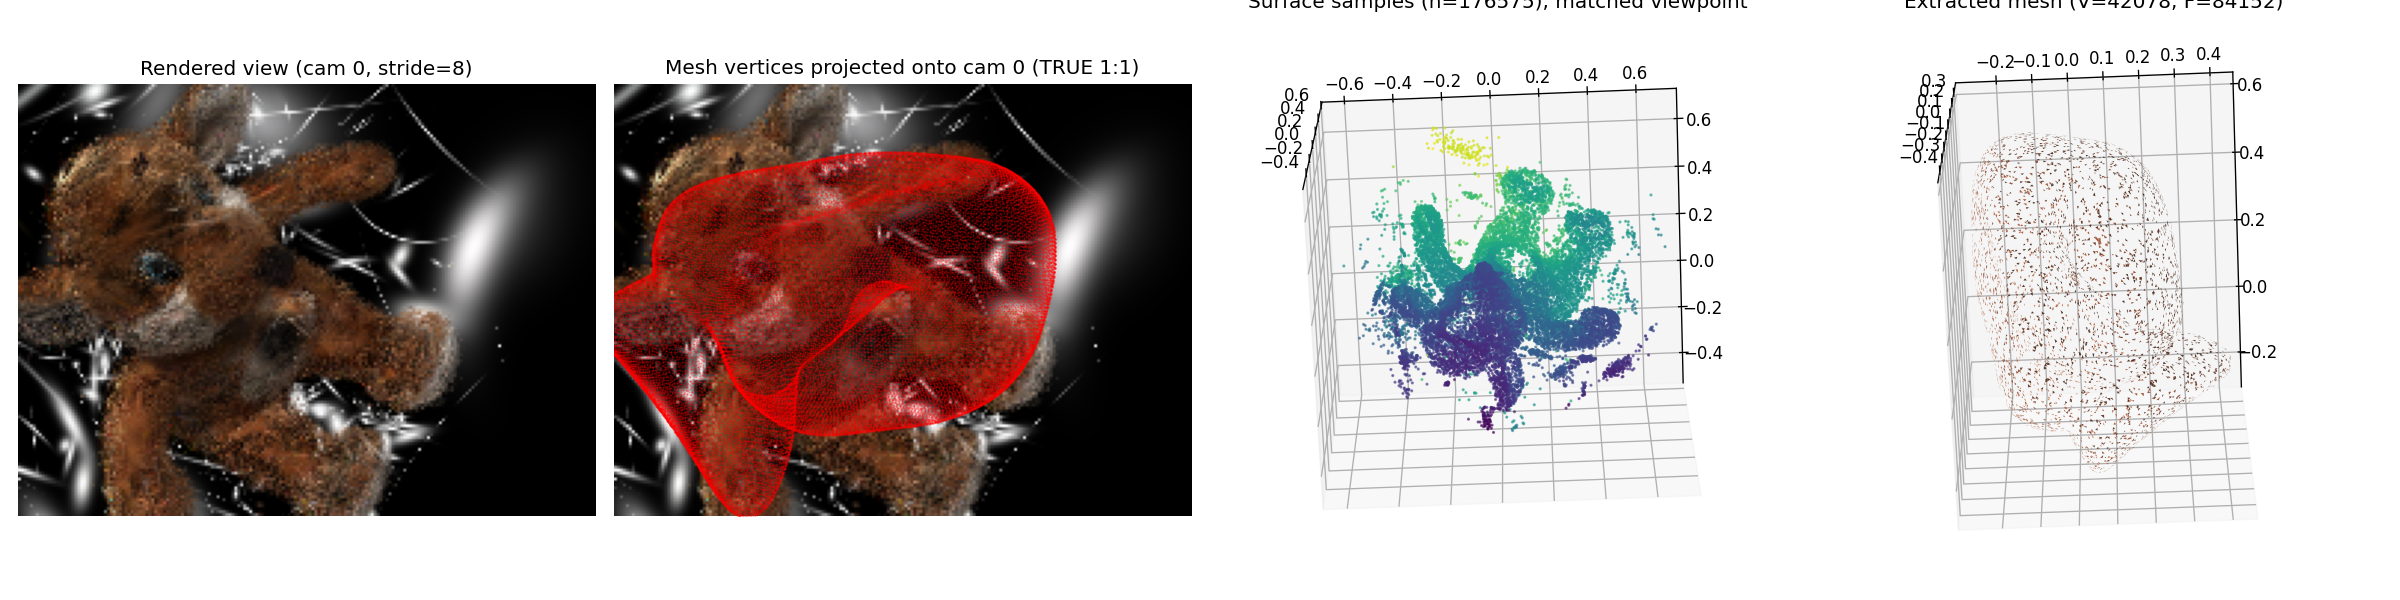

[03:02:14] [DISPLAY] showing /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-c883ba8f953a9f17/pipeline_visualization.png inline above


In [28]:
try:
    import sys
    for mod in list(sys.modules):
        if mod == "matplotlib" or mod.startswith("matplotlib.") or mod.startswith("mpl_toolkits"):
            del sys.modules[mod]
    
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
    from IPython.display import Image, display  # needed because Agg makes plt.show() a no-op
    
    tc = CFG["transmittance"]
    VIZ_CAM_IDX = DIAG_CAM_IDX if "DIAG_CAM_IDX" in dir() else 0
    viz_cam = cams[VIZ_CAM_IDX]
    viz_stride = EVAL_RENDER_STRIDE
    
    # --- Render this exact camera using the CURRENT (post-refinement) gauss_f ---
    o_viz, d_viz, (ys_viz, xs_viz) = viz_cam.rays(DEVICE, stride=viz_stride)
    
    def _render_chunked(model, origins, directions, batch_size):
        chunks = []
        for start in range(0, len(origins), batch_size):
            end = min(start + batch_size, len(origins))
            with torch.no_grad():
                rgb = render_rays(
                    model, origins[start:end], directions[start:end],
                    tc["cull_sigma"], tc["max_candidates_per_ray"],
                )
            chunks.append(rgb.detach().cpu())
            del rgb
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
        return torch.cat(chunks, dim=0).numpy()
    
    img_flat = _render_chunked(gauss_f, o_viz, d_viz, EVAL_RENDER_BATCH_SIZE)
    uy, ux = np.unique(ys_viz), np.unique(xs_viz)
    img_pred = img_flat.reshape(len(uy), len(ux), 3)
    
    # --- TRUE 1:1 projected overlay, for the extracted MESH vertices ---
    V = np.asarray(mesh_for_viz.vertices)
    Vc = (viz_cam.R @ V.T).T + viz_cam.t
    in_front = Vc[:, 2] > 1e-6
    Vc = Vc[in_front]
    uvw = (viz_cam.K @ Vc.T).T
    u_px = uvw[:, 0] / uvw[:, 2]
    v_px = uvw[:, 1] / uvw[:, 2]
    in_frame = (u_px >= 0) & (u_px < viz_cam.W) & (v_px >= 0) & (v_px < viz_cam.H)
    u_px, v_px = u_px[in_frame], v_px[in_frame]
    log(f"Mesh vertices projected into cam {VIZ_CAM_IDX}: "
        f"{len(u_px)}/{len(V)} land inside the frame in front of the camera "
        f"({100*len(u_px)/len(V):.1f}%)")
    
    # --- matched-viewpoint math ---
    scene_center = (np.array(bounds_min) + np.array(bounds_max)) / 2.0
    view_dir = viz_cam.center - scene_center
    r_xy = np.hypot(view_dir[0], view_dir[1])
    viz_elev = float(np.degrees(np.arctan2(view_dir[2], r_xy)))
    viz_azim = float(np.degrees(np.arctan2(view_dir[1], view_dir[0])))
    
    fig = plt.figure(figsize=(20, 5))
    
    # 1. Rendered view (post-refinement gauss_f)
    ax1 = fig.add_subplot(1, 4, 1)
    ax1.imshow(np.clip(img_pred, 0, 1), extent=[0, viz_cam.W, viz_cam.H, 0])
    ax1.set_title(f"Rendered view (cam {VIZ_CAM_IDX}, stride={viz_stride})")
    ax1.axis("off")
    
    # 2. TRUE 1:1 mesh-vertex overlay on the rendered view
    ax2 = fig.add_subplot(1, 4, 2)
    ax2.imshow(np.clip(img_pred, 0, 1), extent=[0, viz_cam.W, viz_cam.H, 0])
    ax2.scatter(u_px, v_px, s=1.5, c="red", alpha=0.35, linewidths=0)
    ax2.set_xlim(0, viz_cam.W)
    ax2.set_ylim(viz_cam.H, 0)
    ax2.set_title(f"Mesh vertices projected onto cam {VIZ_CAM_IDX} (TRUE 1:1)")
    ax2.axis("off")
    
    # 3. Surface samples -- matched viewpoint, true aspect ratio, full 20k subsample
    ax3 = fig.add_subplot(1, 4, 3, projection="3d")
    sp = surface_points.numpy()
    rng = np.random.default_rng(SEED + 300)
    sub = sp[rng.choice(len(sp), size=min(20000, len(sp)), replace=False)]
    ax3.scatter(sub[:, 0], sub[:, 1], sub[:, 2], s=0.8, c=sub[:, 2], cmap="viridis", alpha=0.6)
    full_ptp = np.ptp(sp, axis=0)
    ax3.set_box_aspect(tuple(full_ptp))
    ax3.view_init(elev=viz_elev, azim=viz_azim)
    ax3.set_title(f"Surface samples (n={len(sp)}), matched viewpoint")
    
    # 4. Extracted mesh -- matched viewpoint + true aspect ratio, real face render
    ax4 = fig.add_subplot(1, 4, 4, projection="3d")
    f_ = np.asarray(mesh_for_viz.faces)
    rng2 = np.random.default_rng(SEED + 301)
    sub_f = f_[rng2.choice(len(f_), size=min(4000, len(f_)), replace=False)]
    ax4.plot_trisurf(V[:, 0], V[:, 1], V[:, 2], triangles=sub_f, color=(0.7, 0.35, 0.2, 0.9), linewidth=0)
    mesh_ptp = np.ptp(V, axis=0)
    ax4.set_box_aspect(tuple(mesh_ptp))
    ax4.view_init(elev=viz_elev, azim=viz_azim)
    ax4.set_title(f"Extracted mesh (V={len(V)}, F={len(f_)})")
    
    plt.tight_layout()
    visualization_path = RUN_DIR / "pipeline_visualization.png"
    plt.savefig(visualization_path, dpi=120)
    plt.close(fig)  # Agg backend never draws to screen -- close instead of leaking the figure
    log(f"[SAVE] {visualization_path}")
    
    # --- Explicit inline display, since plt.show() is a silent no-op under Agg. ---
    # This guarantees what you see in THIS cell's output is byte-identical to the
    # file actually saved to RUN_DIR just above -- no more stale screenshots.
    display(Image(filename=str(visualization_path)))
    log(f"[DISPLAY] showing {visualization_path} inline above")
    print("\n[SUCCESS] Processing Stage completed without errors.")
except Exception as e:
    import traceback
    traceback.print_exc()
    print(f"\n[FAILED] Processing Stage encountered an error: {e}")
    raise



## 19. Final result manifest


In [27]:
try:
    results = {
        "run_hash": RUN_HASH,
        "run_directory": str(RUN_DIR),
        "scan_name": scan_name,
        "using_synthetic_scene": USING_SYNTHETIC,
        "using_synthetic_cameras": USING_SYNTHETIC_CAMERAS,
        "using_synthetic_photometric_target": USING_SYNTHETIC_PHOTOMETRIC_TARGET,
        "n_gaussians_loaded": len(gauss),
        "n_gaussians_after_opacity_filter": len(gauss_f),
        "n_surface_samples": int(len(surface_points)),
        "n_refinement_iterations": N_ITERS,
        "training_checkpoint": str(TRAIN_CHECKPOINT),
        "mesh_for_metrics": str(METRIC_MESH_PATH),
        "mesh_for_visualization": str(VIZ_MESH_PATH),
        "geometry": geometry_results,
        "rendering": render_results,
        "loss_history_final": loss_history[-1] if loss_history else None,
    }
    with open(FINAL_RESULTS_PATH, "w") as fp:
        json.dump(results, fp, indent=2)
    log(f"[SAVE] final results: {FINAL_RESULTS_PATH}")
    print(json.dumps(results, indent=2))
    
    print("\n[SUCCESS] Processing Stage completed without errors.")
except Exception as e:
    import traceback
    traceback.print_exc()
    print(f"\n[FAILED] Processing Stage encountered an error: {e}")
    raise



[02:13:44] [SAVE] final results: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-c883ba8f953a9f17/results.json
{
  "run_hash": "c883ba8f953a9f17",
  "run_directory": "/notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-c883ba8f953a9f17",
  "scan_name": "scan105",
  "using_synthetic_scene": false,
  "using_synthetic_cameras": false,
  "using_synthetic_photometric_target": true,
  "n_gaussians_loaded": 225500,
  "n_gaussians_after_opacity_filter": 204616,
  "n_surface_samples": 176575,
  "n_refinement_iterations": 3000,
  "training_checkpoint": "/notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-c883ba8f953a9f17/02_training_checkpoint.pt",
  "mesh_for_metrics": "/notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-c883ba8f953a9f17/04_mesh_for_metrics.ply",
  "mesh_for_visualization": "/notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-c883ba8f953a9f17/04_mesh_for_visualization.ply",
 

print(CFG["joint_refinement"]["n_iterations_smoke_test"])
print(CFG["joint_refinement"]["batch_size_rays_smoke_test"])
print(CFG["mesh_extraction"]["grid_resolution_smoke_test"])## 20. Restart and failure recovery guide

The notebook prints `[RUN]`, `[SAVE]`, `[LOAD]`, `[SKIP]`, `[RESET]`, or
`[STALE]` at every expensive boundary. Artifacts live in the printed
`RUN_DIR` and are never stored only in notebook output.

| Failure area | Durable artifact already available | What a later `Run All` does |
|---|---|---|
| Dataset/environment | Kaggle/local dataset cache | Re-discovers the same data and validates the run identity |
| Surface extraction | `01_surface_samples.pt` | Loads samples instead of repeating all camera rays |
| Joint refinement | `02_training_checkpoint.pt` every 25 iterations | Resumes at `next_iteration`; skips entirely when complete |
| Mesh extraction/postprocess | raw `.npz` plus both `.ply` meshes | Loads meshes; evaluation changes do not run training |
| GT/alignment or geometric metrics | `05_geometry_results.json` | Rerun only Evaluation A and B after editing them |
| Rendering metrics | `06_render_results.json` | Rerun only Evaluation C with a safer stride/batch if necessary |
| Final summary | `results.json` | Rebuilds the manifest from the stage-specific results |

For strict benchmark reporting, prefer a dataset-provided `scale_mat` and set
`EVAL_ALIGNMENT_MODE="scale_mat"`. The automatic similarity-ICP fallback uses
the ground truth for registration and is therefore explicitly labeled as a
registration-assisted diagnostic. DTU scanner point clouds use millimetres, so
the configured `0.001/0.005 m` F-score thresholds are evaluated as `1/5 mm`.

The original notebook outputs were cleared to prevent the old `stl001`,
unaligned Chamfer, and zero F-score values from being mistaken for results of
this corrected pipeline.


## 17. Cleanup

To prevent storage from stacking up on repeated runs, this cell removes the downloaded Kaggle datasets from the cache.

In [ ]:
try:
    import shutil
    if 'kaggle_3dgs_dir' in globals() and kaggle_3dgs_dir:
        print(f"Cleaning up {kaggle_3dgs_dir}...")
        shutil.rmtree(kaggle_3dgs_dir, ignore_errors=True)
    if 'kaggle_gt_dir' in globals() and kaggle_gt_dir:
        print(f"Cleaning up {kaggle_gt_dir}...")
        shutil.rmtree(kaggle_gt_dir, ignore_errors=True)
    print("\n[SUCCESS] Cleanup completed without errors.")
except Exception as e:
    import traceback
    traceback.print_exc()
    print(f"\n[FAILED] Cleanup encountered an error: {e}")
